# 00. Data Exploration & Pipeline Design: Substack newsletter dataset

This notebook explores the dataset of **3.5 million posts** to determine which content should be fed into the topic model and to understand the characteristics of the remaining data.

Each analytical section concludes with two clear takeaways:
* **Observations:** The data metrics and what they reveal.
* **Decisions:** Practical choices made for the final cleaning pipeline and their rationale.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import os

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import math
import logging
logging.basicConfig(level=logging.INFO)

from substack_topics.data.load import *
from substack_topics.data.explore import *
from substack_topics.plots import *

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
# Configuration for data paths, file names, and other constants
KAGGLE_HANDLE = "reja37/substack-newsletter-articles-and-metadata-3-5m"
RAW_DATA_PATH = Path("../data/raw/substack_dataset")
INTERIM_DATA_PATH = Path("../data/interim/substack_dataset")
RAW_FILE_NAME = "substack_v1.parquet"
INTERIM_FILE_NAME = "substack_processed.parquet"
LANGUAGE_DETECTION_MODEL_PATH = Path("../data/interim/fasttext/lid.176.ftz")

SEED = 42
MIN_PLAUSIBLE_DATE = "2017-10-16"    # Substack launched in 2017: earlier dates are likely to be imports or errors
MIN_PLAUSIBLE_YEAR = pd.to_datetime(MIN_PLAUSIBLE_DATE).year

## 1. Download and load

- Downloads the Kaggle dataset only if the parquet file is missing (about 650 MB, one-off), then loads it. 
- `load_raw` works with `fastparquet` installed.
- Datasource: https://www.kaggle.com/datasets/reja37/substack-newsletter-articles-and-metadata-3-5m/data

In [3]:
if not RAW_DATA_PATH.exists():
    download_kaggle_dataset(KAGGLE_HANDLE, RAW_DATA_PATH)
print("Using:", RAW_DATA_PATH)
    
df = load_raw(RAW_DATA_PATH/RAW_FILE_NAME)
print("shape of dataframe:", df.shape)

Using: ../data/raw/substack_dataset
shape of dataframe: (3513881, 10)


## 2. Overview

In [4]:
# Display random sample of dataframe without author names
display(safe_view(df, n=20, mask=None, seed=SEED))

,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category
1422317,https://santikaro.substack.com,Ain't Us Against Them,https://santikaro.substack.com/p/aint-us-against-them,2025-05-02 23:36:38,"When we think it's us against them, that against locks us into flip-flopping between f...",21,4,1,Technology & AI
170134,https://nothing867384.substack.com,نص بعنوان: ورده في التراب.\nاتمنى أن ينال إعجابكم,https://nothing867384.substack.com/p/8ef,2025-07-23 08:16:18,&#1608;&#1601;&#1610; &#1575;&#1604;&#1610;&#1608;&#1605; &#1575;&#1604;&#1584;&#1610;...,48,8,1,General & Uncategorized
2076946,https://practicemakesculture.substack.com,Co-Create Working Agreements,https://practicemakesculture.substack.com/p/co-create-working-agreements,2025-07-16 14:57:04,"Amazing leaders, we hope the first half of your year went great.",28,3,1,"Culture, Arts & Literature"
1590541,https://arwadamon.substack.com,I did not deserve to be forgiven with such grace for failing.,https://arwadamon.substack.com/p/i-almost-cried-because-i-couldnt,2026-08-09 14:59:10,My brain just wanted to save one thing in Gaza.,61,12,1,Technology & AI
2599994,https://calliebates.substack.com,Following tracks,https://calliebates.substack.com/p/following-tracks,2025-02-13 14:13:03,Finding a little hope in a corner of the wild,16,2,1,General & Uncategorized
2520701,https://elizabethjannuzzi.substack.com,[rerun] Unpacking Concerns About College Binge-Drinking,https://elizabethjannuzzi.substack.com/p/rerun-unpacking-concerns-about-college-cf2,2026-08-24 10:23:23,"I have no answers, but lots of opinions!",55,6,1,General & Uncategorized
908658,https://wayetu.substack.com,faith,https://wayetu.substack.com/p/faith,2025-04-08 20:19:27,reflection(s),5,1,1,Technology & AI
846,https://regianefolter.substack.com,Impressões sobre a vida com um bebê,https://regianefolter.substack.com/p/impressoes-sobre-a-vida-com-um-bebe,2026-04-29 23:01:05,Quatro meses de duas novas vidas,35,7,1,General & Uncategorized
262210,https://avllit.substack.com,When the Universe Reads the Room,https://avllit.substack.com/p/when-the-universe-reads-the-room,2026-06-03 15:53:15,A graduation trip leads to love for Godmothers and a stack of cool summer reads.,32,6,1,Personal Essays & Stories
288226,https://halikarla.substack.com,When We Yearn to Connect With Nature,https://halikarla.substack.com/p/when-we-yearn-to-connect-with-nature,2024-06-30 12:31:03,how we look and listen shapes our lives | June 2024,36,7,1,General & Uncategorized


In [5]:
# Check the structure and non-null counts of the dataframe
print(df.info(show_counts=True))
# Display summary statistics for numeric columns
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3513881 entries, 0 to 3513880
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   publication_domain  3513881 non-null  object        
 1   post_title          3513881 non-null  object        
 2   article_url         3513881 non-null  object        
 3   author_name         3513881 non-null  object        
 4   publish_date        3513881 non-null  datetime64[us]
 5   subtitle_summary    3513881 non-null  object        
 6   title_char_length   3513881 non-null  int64         
 7   title_word_count    3513881 non-null  int64         
 8   has_subtitle        3513881 non-null  int32         
 9   category            3513881 non-null  object        
dtypes: datetime64[us](1), int32(1), int64(2), object(6)
memory usage: 254.7+ MB
None


,publish_date,title_char_length,title_word_count,has_subtitle
count,3513881,"3,513,881.000","3,513,881.000","3,513,881.000"
mean,2025-09-20 06:47:22.273352,38.713,6.664,1.000
min,0001-03-08 08:50:02,0.000,1.000,0.000
25%,2025-05-22 17:17:32,22.000,4.000,1.000
50%,2026-03-15 14:31:06,34.000,6.000,1.000
75%,2026-07-20 17:38:33,50.000,9.000,1.000
max,2026-09-29 04:55:41,255.000,120.000,1.000
std,NaN,22.945,3.904,0.014


**Observations**
- No nulls in any column, but some titles have length 0. Missing text is stored as empty strings, so a null check finds nothing.
- Each row is a title and a subtitle, with **no article text**. Documents will be very short, which favours embedding models over word-count models.
- `publish_date` looks wrong in places (the minimum is 0001-03-08), so the date column needs its own section.

**Decisions** 
- Check for empty strings, whitespace-only and letter-free text, not only for nulls. Section 6 looks at that.

In [6]:
# Check unique counts and their share for target columns
target_cols = [
    "publication_domain", "post_title", "article_url", 
    "author_name", "subtitle_summary", "category"
]

display(
    df[target_cols]
    .nunique()
    .to_frame(name="unique_count")
    .reset_index(names="column_name")
    .assign(pct_share=lambda x: calculate_percentage(x["unique_count"], len(df)))
)

,column_name,unique_count,pct_share
0,publication_domain,229424,6.529
1,post_title,3321926,94.537
2,article_url,3513881,100.000
3,author_name,223407,6.358
4,subtitle_summary,3267858,92.999
5,category,11,0.000


**Observations**
- 3,513,881 posts, 229,424 publications, 223,407 authors and **11 categories** (dataset card mentioned 10 distinct thematic categories).
- No duplicate URLs. About 94.5% of titles and 93.0% of subtitles are unique, so some text repeats. Section 7 looks at that.

## 3. Dates

- From the overview section, the `publish_date` is `datetime64[us]` ranging from `0001-03-08` to `2026-09-29`. 
- Investigate which early dates are **errors** (year 1, year 24) and which are **genuine backdated imports** (a blog migrated to Substack keeps its original dates).

In [7]:
# Yearly breakdown of articles
year_series = df["publish_date"].dt.year

# Calculate the number of brand-new domains cohort year-by-year
new_domains_by_year = (
    df.groupby("publication_domain")["publish_date"].min()  
    .dt.year                                
    .value_counts()
    .to_frame(name="new_domains_count")
)
yearly_report_df = (df.groupby(year_series)
    .agg(
        posts_count=("article_url", "nunique"),                 
        domains_count=("publication_domain", "nunique")
    )
    .rename_axis("publish_year")
    .assign(
        posts_yearly_change=lambda x: (x["posts_count"].pct_change() * 100).round(1),
        domains_yearly_change=lambda x: (x["domains_count"].pct_change() * 100).round(1)
    )
    .join(new_domains_by_year, how="left") 
    .fillna({"new_domains_count": 0})
    .astype({"new_domains_count": int})
    .reset_index())
yearly_report_df

,publish_year,posts_count,domains_count,posts_yearly_change,domains_yearly_change,new_domains_count
0,1,3,2,NaN,NaN,2
1,2,6,6,100.000,200.000,6
2,24,2,2,-66.700,-66.700,2
3,1924,1,1,-50.000,-50.000,1
4,2003,1,1,0.000,0.000,1
5,2004,1,1,0.000,0.000,0
6,2005,3,1,200.000,0.000,0
7,2006,3,1,0.000,0.000,0
8,2007,1,1,-66.700,0.000,0
9,2008,10,3,900.000,200.000,2


In [8]:
# Check articles published before substack launched dates
early_dates_mask = df["publish_date"] < MIN_PLAUSIBLE_DATE
(df.loc[early_dates_mask, ["article_url", "publication_domain"]]
    .nunique()
    .to_frame(name="unique_count")
    .reset_index(names="column_name")
    .assign(pct_share=lambda x: calculate_percentage(x["unique_count"], len(df)))
    )

,column_name,unique_count,pct_share
0,article_url,878,0.025
1,publication_domain,194,0.006


In [9]:
# Check articles from weird dates before 1924
display(safe_view(df, n=5, mask=df["publish_date"] <= "1924-01-01", seed=SEED).sort_values("publish_date"))
# Check articles before substack launch date
display(safe_view(df, n=5, mask=early_dates_mask, seed=SEED).sort_values("publish_date"))

,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category
1560504,https://tomasbjartur.substack.com,Rational Teletubbies,https://tomasbjartur.substack.com/p/rational-teletubbies-a91,1-08-02 22:34:58,Tinky Winky was a fetal prodigy. He knew how to count before he was born. His mother's...,20,2,1,"Culture, Arts & Literature"
282379,https://poedat.substack.com,Sıkça Sorulan Sorular,https://poedat.substack.com/p/sikca-sorulan-sorular,2-01-01 21:03:15,"Etkinliklerimiz ba&#351;vuru temelli, kay&#305;t temelli, herkese a&#231;&#305;k ve &#...",21,3,1,General & Uncategorized
943456,https://bodyhaireverywhere.substack.com,The first time I let my leg hair grow,https://bodyhaireverywhere.substack.com/p/the-first-time-i-let-my-leg-hair,2-04-17 12:11:39,"<div class=""captioned-image-container""><figure><a class=""image-link image2 is-viewable...",37,9,1,Technology & AI
3241764,https://beyondstreetphotography.substack.com,Conversation with NYC Street Photographer Robert Virga,https://beyondstreetphotography.substack.com/p/conversation-with-nyc-street-photographer,2-05-02 20:23:02,During the early Covid years I became a fan of the Leica Conversation videos on YouTub...,54,7,1,Food & Travel
3229738,https://lennertesser.substack.com,Het bizarre begin van mijn kankerdiagnose,https://lennertesser.substack.com/p/het-bizarre-begin-van-mijn-kankerdiagnose,2-06-28 21:22:30,Spoiler alert: het was geen ontsteking,41,6,1,General & Uncategorized


,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category
818203,https://caterina.substack.com,"Measure, Hölderlin & Tehching Hsieh",https://caterina.substack.com/p/measure-hlderlin-and-tehching-hsieh,1-03-08 08:50:02,Is there measure on earth? There is None.,35,5,1,"Culture, Arts & Literature"
970003,https://jamiequint.substack.com,Retention Is King,https://jamiequint.substack.com/p/retention-is-king,2014-06-12 22:57:24,This was originally posted as a guest post on Andrew Chen's blog here. -- There are to...,17,3,1,Finance & Crypto
1231525,https://priyavadhyar.substack.com,where the true self roams free,https://priyavadhyar.substack.com/p/where-true-self-roams-free,2015-12-14 02:27:00,* Sometimes you have to shrink in size to really see a painting.,30,6,1,Technology & AI
3168976,https://bethain.substack.com,"Writer, Interrupted",https://bethain.substack.com/p/writer-interrupted,2016-05-05 21:54:27,I have a good friend who is more of a hippie than I am&#8212;more believing in afterli...,19,2,1,Technology & AI
1277875,https://kevinmayes.substack.com,"Making Charcoal at Charlton Court Farm, Steyning, West Sussex circa 1991.",https://kevinmayes.substack.com/p/making-charcoal-at-charlton-court-farmhtml,2016-09-17 01:56:00,"Making Charcoal at Charlton Court Farm, Steyning, West Sussex circa 1991 (click this l...",73,11,1,General & Uncategorized


In [10]:
early_dates_by_publication = (df[early_dates_mask].groupby("publication_domain")["article_url"]
    .nunique()
    .to_frame(name="unique_count")
    .sort_values(by="unique_count", ascending=False)
    .assign(pct_share=lambda x: calculate_percentage(x["unique_count"], early_dates_mask.sum()))
    )
display(early_dates_by_publication)
display(safe_view(df, n=5, mask=df["publication_domain"]==early_dates_by_publication.index[0], seed=SEED).sort_values("publish_date"))

,unique_count,pct_share
publication_domain,,
https://echen.substack.com,19,2.164
https://braudelpapers.substack.com,17,1.936
https://magigibson.substack.com,16,1.822
https://michaeljohns.substack.com,16,1.822
https://207permaculture.substack.com,15,1.708
...,...,...
https://maxpeters.substack.com,1,0.114
https://marissafindsahobby.substack.com,1,0.114
https://luxuryretailmarket.substack.com,1,0.114


,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category
487637,https://echen.substack.com,Information Transmission in a Social Network: Dissecting the Spread of a Quora Post,https://echen.substack.com/p/information-transmission-in-a-social-network-dissecting-t...,2011-09-07 02:15:00,tl;dr See this movie visualization for a case study on how a post propagates through Q...,83,13,1,"Culture, Arts & Literature"
1694900,https://echen.substack.com,Winning the Netflix Prize: A Summary,https://echen.substack.com/p/winning-the-netflix-prize-a-summary,2011-10-24 02:15:00,How was the Netflix Prize won?,36,6,1,General & Uncategorized
202118,https://echen.substack.com,Introduction to Conditional Random Fields,https://echen.substack.com/p/introduction-to-conditional-random-fields,2012-01-02 23:00:00,"Imagine you have a sequence of snapshots from a day in Justin Bieber's life, and you w...",41,5,1,Food & Travel
2705154,https://echen.substack.com,Instant Interactive Visualization with d3 + ggplot2,https://echen.substack.com/p/instant-interactive-visualization-with-d3-and-ggplot2,2012-03-05 03:15:00,It's often easier to understand a chart than a table.,51,7,1,"Culture, Arts & Literature"
3198719,https://echen.substack.com,Soda vs. Pop with Twitter,https://echen.substack.com/p/soda-vs-pop-with-twitter,2012-07-06 02:15:00,One of the great things about Twitter is that it's a global conversation anyone can jo...,25,5,1,Food & Travel


**Observation: dates before Substack launched**
- 878 posts from 194 publications are dated before Substack launched (2017-10-16), which is 0.025% of all posts.
- Dates such as 2014 look like genuine back-dated imports from older blogs. Years 1, 2 and 24 are parse errors.

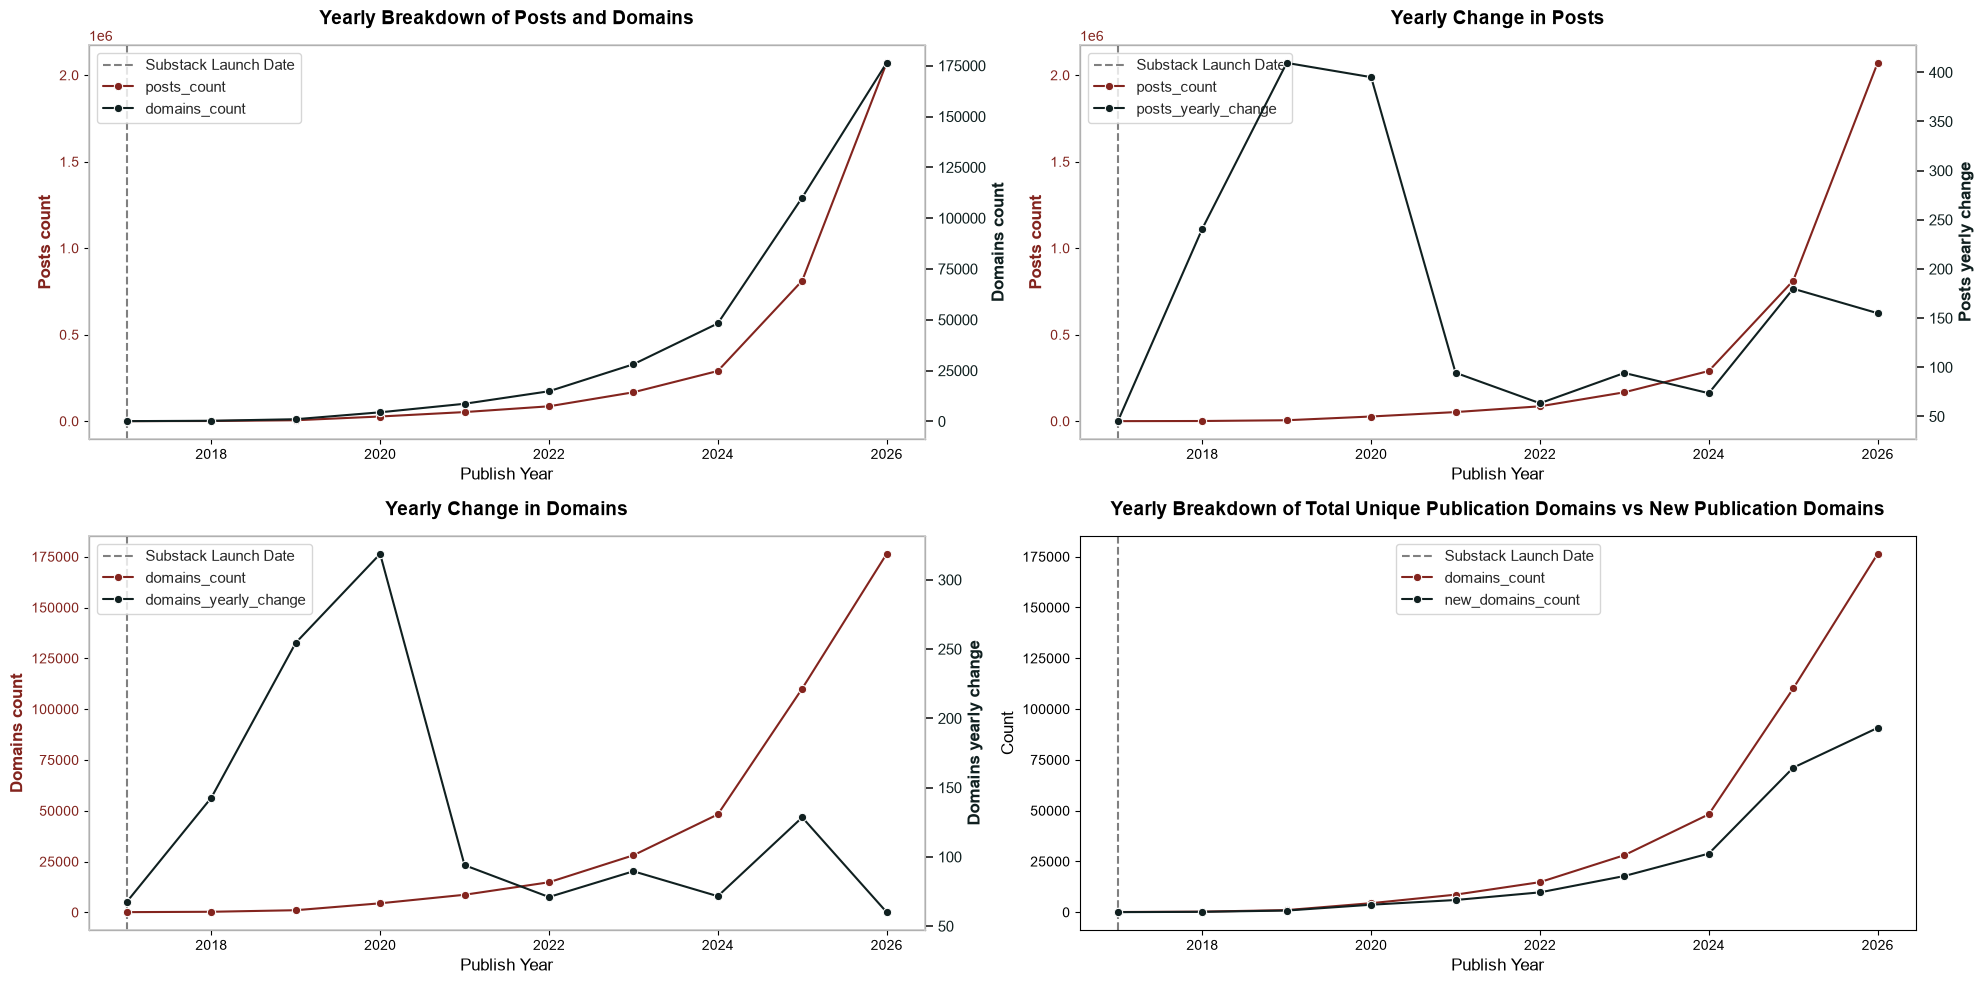

In [11]:
nrows = 2
ncols = 2
fig, axes = apply_custom_theme(figsize=(20, nrows * 5), nrows=nrows, ncols=ncols)

# List of column definitions for subplots
subplots_config = [
    {"y1": "posts_count", "y2": "domains_count", "title": "Yearly Breakdown of Posts and Domains"},
    {"y1": "posts_count", "y2": "posts_yearly_change", "title": "Yearly Change in Posts"},
    {"y1": "domains_count", "y2": "domains_yearly_change", "title": "Yearly Change in Domains"},
    {"y1": "domains_count", "y2": "new_domains_count", "title": "Yearly Breakdown of Total Unique Publication Domains vs New Publication Domains"},
]

for idx, ax in enumerate(axes):
    if idx >= len(subplots_config):
        ax.axis('off')
        continue
    config = subplots_config[idx]
    
    if idx < 3:
        plot_dual_axis_subplot(
            ax1=ax,
            df=yearly_report_df[yearly_report_df.publish_year >= MIN_PLAUSIBLE_YEAR],
            x="publish_year",
            y1=config["y1"],
            y2=config["y2"],
            title=config["title"],
            ylabel1=config["y1"].capitalize().replace("_", " "),
            ylabel2=config["y2"].capitalize().replace("_", " "),
            xlabel="Publish Year",
            vline_value=MIN_PLAUSIBLE_YEAR,
            vline_label="Substack Launch Date",
        )
    else:
        plot_line_chart_subplot(
            ax=ax,
            df=yearly_report_df[yearly_report_df.publish_year >= MIN_PLAUSIBLE_YEAR],
            x="publish_year",
            y=[config["y1"],config["y2"]],
            title=config["title"],
            ylabel="Count",
            xlabel="Publish Year",
            vline_value=MIN_PLAUSIBLE_YEAR,
            vline_label="Substack Launch Date"
        )

plt.tight_layout()
plt.show()

In [12]:
df["publish_year"] = df["publish_date"].dt.year
date_mask = df.publish_date >= MIN_PLAUSIBLE_DATE
print(f"Minimum publish date after min plausible date: {df[date_mask]['publish_date'].min()}")

print(f"Proportion of posts published in 2025 or later: {len(df[df.publish_year >= 2025])/len(df)*100:.2f}%")
print(f"Ratio of posts published in 2026 to those in 2020: {len(df[df.publish_year == 2026])/len(df[df.publish_year == 2020]):.2f}")
print(f"Proportion of new domains in 2025 or later: {yearly_report_df[yearly_report_df.publish_year >= 2025]['new_domains_count'].sum()/yearly_report_df[yearly_report_df.publish_year >= 2025]['domains_count'].sum()*100:.2f}%")


analysis_start_date = pd.to_datetime("2018-01-01")
print(f"Number of posts published before the analysis start date: {len(df[df.publish_date < analysis_start_date])}")
print(f"Maximum publish date: {df[df.publish_date >= analysis_start_date]['publish_date'].max()}")

Minimum publish date after min plausible date: 2017-10-16 08:45:00
Proportion of posts published in 2025 or later: 82.05%
Ratio of posts published in 2026 to those in 2020: 76.43
Proportion of new domains in 2025 or later: 56.51%
Number of posts published before the analysis start date: 965
Maximum publish date: 2026-09-29 04:55:41


**Observation: volume over time**
- The number of posts and domains climb steeply over the years.
- Year 2017-2019 saw a sharp increase in the yearly increase in the number of posts and domains but the counts were still relatively much lower compared to later years.
- Year 2020-2024 saw a general acceleration in the growth of posts and domains, with the growth generally almost doubling year over year.
- Year 2025 onwards, the growth starts to spike to even higher levels of yearly growth, indicating a rapid increase in both posts and domains.
- **82% of all posts are from 2025 and 2026.** Posts per year grew from 27,096 in 2020 to 2,071,080 in 2026, about 76 times.
- New publications appear every year, so the growth comes from both more publications and more posts per publication. 57% of all publication domains from 2025 and 2026 are new to substack platform.

**Decisions** 
- Analysis window from **2018-01-01** to **2026-09-29**. 
- The analysis window begins on 2018-01-01 to ensure the use of full calendar years following the minimum available date (2017-10-16).
- Only 965 rows (0.03%) fall outside it, so the start date matters for removing impossible dates, not for volume. 
- Any trend analysis must use **shares of each year**, not raw counts, because raw counts mostly measure the growth of the platform.

## 4. Types of Article Categories

- The dataset card mention that post metadata and titles are classified into 10 distinct thematic categories from **rule-based topic classification**, using high-performance regex matching.
- Analyse the concentration of data across categories.

,category,posts_count,domains_count,post_pct_share,domains_pct_share
0,General & Uncategorized,1299846,179532,36.992,19.505
1,Technology & AI,774230,175358,22.033,19.052
2,"Culture, Arts & Literature",417911,130535,11.893,14.182
3,Politics & News,247472,97615,7.043,10.605
4,Finance & Crypto,202112,63416,5.752,6.890
5,Personal Essays & Stories,182959,82938,5.207,9.011
6,Food & Travel,151753,72273,4.319,7.852
7,Health & Wellness,84162,38818,2.395,4.217
8,Business & Startups,67295,33527,1.915,3.643
9,Sports,57200,28220,1.628,3.066


Gini coefficient for posts per category: 0.551


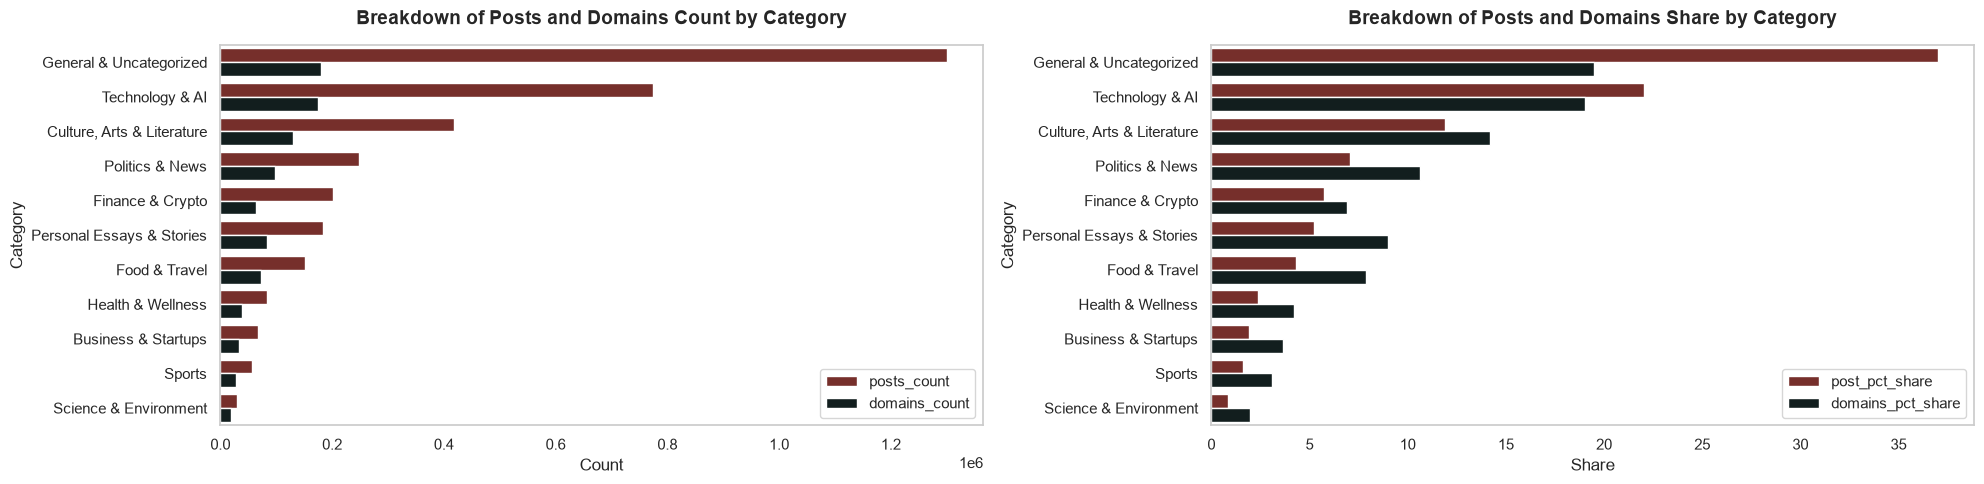

In [13]:
# Category-level Breakdown of Posts and Domains
by_categories = (
    df.groupby("category")
    .agg(
        posts_count=("article_url", "nunique"),                 
        domains_count=("publication_domain", "nunique")
    )
    .assign(post_pct_share=lambda x: calculate_percentage(x["posts_count"], df.article_url.nunique()))
    .assign(domains_pct_share=lambda x: calculate_percentage(x["domains_count"], x["domains_count"].sum()))
    .sort_values(by="posts_count", ascending=False)
    .reset_index()
    )
display(by_categories)
print(f"Gini coefficient for posts per category: {gini(by_categories['posts_count']):.3f}")

ncols = 2
nrows = 1
fig, axes = apply_custom_theme(figsize=(20, nrows * 5), nrows=nrows, ncols=ncols)

# List of column definitions for subplots
subplots_config = [
    {"x1": "posts_count", "x2": "domains_count", "title": "Breakdown of Posts and Domains Count by Category"},
    {"x1": "post_pct_share", "x2": "domains_pct_share", "title": "Breakdown of Posts and Domains Share by Category"},
]

for idx, ax in enumerate(axes):
    if idx >= len(subplots_config):
            ax.axis('off')
            continue
    config = subplots_config[idx]
    plot_horizontal_bar_chart_subplot(
        ax=ax,
        df=by_categories,
        y="category",
        x=[config["x1"],config["x2"]],
        title=config["title"],
        ylabel="Category",
        xlabel=config["x1"].split("_")[-1].capitalize(),
    )

plt.tight_layout()
plt.show()

In [14]:
# Check sample posts by category after 2017
df.groupby("category").apply(
    lambda group: safe_view(
        df=group, n=5, 
        cols=["post_title", "subtitle_summary", "article_url"],  # Display only relevant text columns
        mask=date_mask.loc[group.index], 
        seed=SEED
    ))



/var/folders/3g/7zlltyhx3f70qrpjz4by80rm0000gn/T/ipykernel_35734/4089626998.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("category").apply(


post_title  \
category                                                                                                                        
Business & Startups        2136752                                               Five stories shaping the photonics landscape   
                           2975723                                                               Finding Your First Customers   
                           2653592                                                          El método reproductivo más eficaz   
                           7485                  Contracts: 15 Legal Clauses You Should Know About (Mini-Series, Part 3 of 5)   
                           60872                                        A conversation with AC Chen (1st employee @ Flexport)   
Culture, Arts & Literature 122026                                                     shoot your shot: events heading to fdlm   
                           3362675           Restoring the Accountability Pillar:\nA Battle Plan to Defend American Democracy   
                           1114176                                         100 Movie Challenge #43: The Scarlet and the Black   
                           2288308                                                                              I am radiant!   
                           2883068  The Residency Days 141-143 - All she did was smile, and say ‘water’ / The Tenth Dimension   
Finance & Crypto           2082080  Tomorrow: I’m Bringing In The Experts To Discuss The Dangote Refinery IPO and How To I...   
                           2823345                                             The $246 Billion Problem Inside Your Household   
                           1078075                                   The Knesset’s Dull Daggers and the Foreign-Funded Circus   
                           2676527                                                                                Coming soon   
                           2917458                                                                        Yiren Digital (YRD)   
Food & Travel              2047476                                                              a girl & her substack account   
                           3348350                                                          Mine Cup Overfloweth with Milketh   
                           1550526                                                                               May 28, 2206   
                           2310786                                                    I Don’t Want to Resent the Life I Chose   
                           1401630                                                                     Traveling vs. Teaching   
General & Uncategorized    891403                                                                          After The Crossing   
                           2144029                                                              ☀️ Orlando for $28 in January   
                           679364                                                                         No esperes respeto.   
                           2212406                                                           let your phone die in your hands   
                           512559                                                                           The $300 Question   
Health & Wellness          2017035  Special 5th Anniversary Health Tip: Sharing Our Team’s Strategies for Staying Spiritua...   
                           722731                                               🍄 Jiu-jitsu is a lot like Super Mario Bros...   
                           1390834                                Renaming SRE outage "post-mortems" for psychological safety   
                           3285776                                                                 The Rise of GLP-1 Skincare   
                           3282879                                                                           Cozy Ca

category,Business & Startups,"Culture, Arts & Literature",Finance & Crypto,Food & Travel,General & Uncategorized,Health & Wellness,Personal Essays & Stories,Politics & News,Science & Environment,Sports,Technology & AI
publish_year,,,,,,,,,,,
2017,2.000,7.000,11.000,5.000,28.000,2.000,2.000,7.000,2.000,3.000,18.000
2018,30.000,101.000,116.000,45.000,411.000,18.000,33.000,81.000,15.000,21.000,203.000
2019,176.000,475.000,621.000,220.000,"1,743.000",107.000,163.000,623.000,61.000,84.000,"1,200.000"
2020,"1,182.000","2,284.000","2,846.000","1,053.000","9,225.000",498.000,997.000,"2,528.000",253.000,531.000,"5,699.000"
2021,"1,714.000","4,547.000","6,332.000","1,962.000","17,758.000","1,066.000","1,957.000","5,297.000",491.000,"1,097.000","10,461.000"
2022,"2,410.000","7,626.000","9,210.000","3,161.000","29,199.000","1,894.000","3,061.000","8,771.000",846.000,"1,642.000","18,241.000"
2023,"4,241.000","17,127.000","13,261.000","6,595.000","60,910.000","3,589.000","7,079.000","12,949.000","1,724.000","3,078.000","36,562.000"
2024,"6,245.000","33,248.000","17,291.000","12,490.000","109,032.000","6,831.000","14,164.000","22,471.000","2,420.000","5,062.000","60,897.000"
2025,"15,253.000","100,401.000","37,875.000","36,296.000","311,880.000","19,768.000","44,179.000","55,652.000","6,859.000","11,812.000","172,209.000"


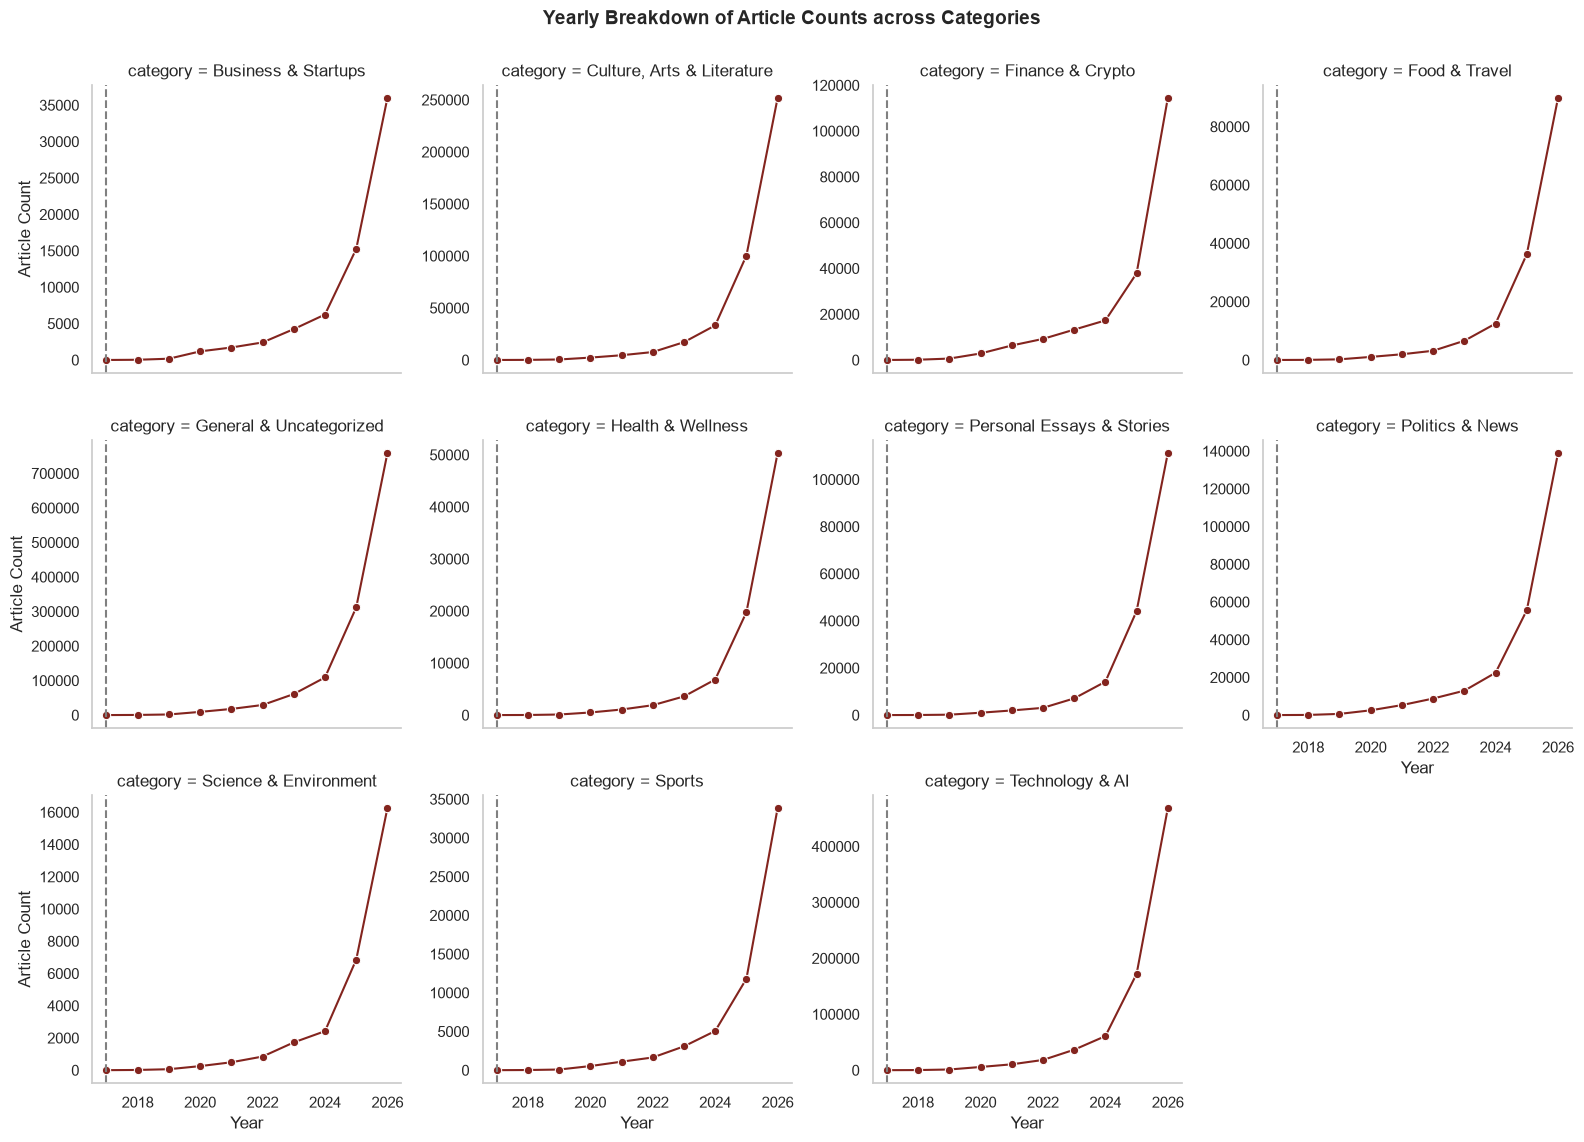

In [15]:
# Year x Category-level Breakdown of Posts
by_year_category = (df[date_mask]
                    .groupby(["publish_year", "category"])["article_url"].nunique()
                    .reset_index(name="post_count")
                    )
display(by_year_category.pivot_table(index="publish_year", columns="category", values="post_count"))

plot_facet_line_chart(
    df=by_year_category,
    x="publish_year",
    y="post_count",
    col="category",
    title="Yearly Breakdown of Article Counts across Categories",
    ylabel="Article Count",
    xlabel="Year",
    vline_value=MIN_PLAUSIBLE_YEAR,
    vline_label="Substack Launch Date",
)

**Observations**
- The dataset card says categories come from **rule-based regex matching**. 37% of posts are General & Uncategorized, and the Gini coefficient across categories is 0.551.
- High percentage of posts and domains are concentrated in a few categories: 22% of posts from Technology & AI and 11.9% of posts from Culture, Arts & Literature.
- A few niche categories exists, such as Science & Environment and Sports, each contributing <5% of posts and domains
- Posts grow in every category, not in a few, so the rise in volume is not a story about one theme.
- Reading random posts per category, the rule-based topic classifcation of category seems to align reasonably well with the title of the posts. 
- However, some labels are plainly wrong: wellness and cocktail posts sit under Technology & AI, and social media and faith posts sit under Sports. The regex might be too loose.

**Decision** 
- **Not** to use `category` as ground truth to score topic models. It stays as a rough context column.

## 5. Publication concentration

- Analyse the concentration of data across publication domains and decide if there is a need to cap posts per publication

In [16]:
by_publication_domain = (
    df.groupby("publication_domain")
    .agg(
        posts_count=("article_url", "nunique"),                 
    )
    .assign(post_pct_share=lambda x: calculate_percentage(x["posts_count"], df.article_url.nunique()))
    .sort_values(by="posts_count", ascending=False)
    .reset_index()
    )
display(by_publication_domain)
display(by_publication_domain.describe())
print(f"Gini coefficient for posts per publication: {gini(by_publication_domain['posts_count']):.3f}")

,publication_domain,posts_count,post_pct_share
0,https://mobydicksummer.substack.com,50,0.001
1,https://michaelmoe.substack.com,50,0.001
2,https://geekincentives.substack.com,29,0.001
3,https://robynyoukilis.substack.com,20,0.001
4,https://robynksneeringer.substack.com,20,0.001
...,...,...,...
229419,https://andthentheycreateus.substack.com,1,0.000
229420,https://wandalyzrivera.substack.com,1,0.000
229421,https://blondelegally.substack.com,1,0.000
229422,https://wandathibodeaux.substack.com,1,0.000


,posts_count,post_pct_share
count,"229,424.000","229,424.000"
mean,15.316,0.001
std,6.653,0.000
min,1.000,0.000
25%,10.000,0.000
50%,20.000,0.001
75%,20.000,0.001
max,50.000,0.001


Gini coefficient for posts per publication: 0.215


In [17]:
# Sample posts of top publication domain by posts count
display(safe_view(df, n=50, mask=df["publication_domain"]==by_publication_domain.publication_domain[0], seed=SEED).sort_values("publish_date"))

,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category,publish_year
90466,https://mobydicksummer.substack.com,Moby-Dick: Chapters 1-2,https://mobydicksummer.substack.com/p/moby-dick-chapters-1-2,2023-05-31 13:01:18,Loomings. The Carpet-Bag.,23,3,1,General & Uncategorized,2023
623669,https://mobydicksummer.substack.com,"Moby-Dick Recap: Etymology, Extracts, and Chapters 1-2",https://mobydicksummer.substack.com/p/moby-dick-recap-etymology-extracts,2023-06-02 13:01:17,"Also, what is up with that Dedication Page, Melville",54,7,1,General & Uncategorized,2023
90465,https://mobydicksummer.substack.com,Moby-Dick: Chapters 3-4,https://mobydicksummer.substack.com/p/moby-dick-chapters-3-4-f74,2023-06-05 13:00:25,The Spouter-Inn. The Counterpane.,23,3,1,General & Uncategorized,2023
2254148,https://mobydicksummer.substack.com,Moby-Dick: Chapters 5-8,https://mobydicksummer.substack.com/p/moby-dick-chapters-5-8-1b1,2023-06-07 13:00:17,Breakfast. The Street. The Chapel. The Pulpit.,23,3,1,General & Uncategorized,2023
1610779,https://mobydicksummer.substack.com,Moby-Dick Recap: Chapters 3-8,https://mobydicksummer.substack.com/p/moby-dick-recap-chapters-3-8-36b,2023-06-09 13:00:55,"Queequeg, Queequeg, Queequeg",29,4,1,General & Uncategorized,2023
2240464,https://mobydicksummer.substack.com,Moby-Dick: Chapters 9-11,https://mobydicksummer.substack.com/p/moby-dick-chapters-9-11-917,2023-06-12 13:01:42,The Sermon. A Bosom Friend. Nightgown.,24,3,1,General & Uncategorized,2023
1788991,https://mobydicksummer.substack.com,Moby-Dick: Chapters 12-15,https://mobydicksummer.substack.com/p/moby-dick-chapters-12-15-232,2023-06-14 13:01:00,Biographical. Wheelbarrow. Nantucket. Chowder.,25,3,1,General & Uncategorized,2023
458487,https://mobydicksummer.substack.com,Moby-Dick Recap: Chapters 9-15,https://mobydicksummer.substack.com/p/moby-dick-recap-chapters-9-15-c3e,2023-06-16 13:01:20,"Ishmael and Queequeg sure are moving fast, even if the novel isn't",30,4,1,General & Uncategorized,2023
2349893,https://mobydicksummer.substack.com,Moby-Dick: Chapters 16-17,https://mobydicksummer.substack.com/p/moby-dick-chapters-16-17-cdd,2023-06-19 13:01:03,The Ship. The Ramadan.,25,3,1,General & Uncategorized,2023
1144500,https://mobydicksummer.substack.com,Moby-Dick: Chapters 18-22,https://mobydicksummer.substack.com/p/moby-dick-chapters-18-22-8cd,2023-06-21 13:01:00,His Mark. The Prophet. All Astir. Going Aboard. Merry Christmas.,25,3,1,General & Uncategorized,2023


**Observations**
- The Gini coefficient of posts per publication is 0.215, which looks like an evenly spread platform. 
- However, the maximum is exactly 50, and the median and 75th percentile are both 20. The balance is highly likely a **side effect of how the data was collected** (it looks like a cap per publication).
- Manual verification of top Substack pages shows that their post counts far exceed the dataset's coverage.
- Consequently, while no single publication dominates the sample, it is difficult to accurately measure true publication volume and prolificacy

**Decisions** 
- No extra cap per publication. The dataset is already capped at 50.

## 6. Text: Length & Quality

- `df.info()` shows that there are **0 null value for every column** in this dataset, yet some titles have title_char_length of 0. 
- Missing text is stored as **empty strings**, not NaN, so a null check misses it. 
- This section analyse empty strings, whitespace-only values, very short values and values with no letters at all.

In [18]:
# Summary of text quality, including length, letter ratio, word count, and presence of HTML, mojibake, and emoji
text_quality_df = text_quality_summary(df)
display(text_quality_df.head(5))
display(text_quality_df.describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

,post_title,subtitle_summary,combined_text,post_title_post_title_decoded,post_title_char_length,post_title_letter_length,post_title_letter_ratio,post_title_is_letter_poor,post_title_word_count,post_title_has_html,...,subtitle_summary_has_emoji,combined_text_combined_text_decoded,combined_text_char_length,combined_text_letter_length,combined_text_letter_ratio,combined_text_is_letter_poor,combined_text_word_count,combined_text_has_html,combined_text_has_mojibake,combined_text_has_emoji
0,When You Break The Holiday Rules,Don't Say No During The Holidays,When You Break The Holiday Rules. Don't Say No During The Holidays,When You Break The Holiday Rules,32,27,0.844,False,6,False,...,False,When You Break The Holiday Rules. Don't Say No During The Holidays,66,53,0.803,False,12,False,False,False
1,"The Only 10 (ok, 20) brands I Want To Wear Right Now - Part 1.","The young labels, quiet growers and almost-famous names I think are worth knowing befo...","The Only 10 (ok, 20) brands I Want To Wear Right Now - Part 1.. The young labels, quie...","The Only 10 (ok, 20) brands I Want To Wear Right Now - Part 1.",62,38,0.613,False,15,False,...,False,"The Only 10 (ok, 20) brands I Want To Wear Right Now - Part 1.. The young labels, quie...",172,127,0.738,False,32,False,False,False
2,Church of Omnipollo,"How a shared obsession with pushing boundaries, and a partnership built on deep respec...","Church of Omnipollo. How a shared obsession with pushing boundaries, and a partnership...",Church of Omnipollo,19,17,0.895,False,3,False,...,False,"Church of Omnipollo. How a shared obsession with pushing boundaries, and a partnership...",138,114,0.826,False,22,False,False,False
3,The Wizard of Oz Movie Series,Investigating the impact of The Wizard of Oz,The Wizard of Oz Movie Series. Investigating the impact of The Wizard of Oz,The Wizard of Oz Movie Series,29,24,0.828,False,6,False,...,False,The Wizard of Oz Movie Series. Investigating the impact of The Wizard of Oz,75,61,0.813,False,14,False,False,False
4,The Day My Son Lost His Phone,and what it taught us about independence,The Day My Son Lost His Phone. and what it taught us about independence,The Day My Son Lost His Phone,29,23,0.793,False,7,False,...,False,The Day My Son Lost His Phone. and what it taught us about independence,71,57,0.803,False,14,False,False,False


,post_title_char_length,post_title_letter_length,post_title_letter_ratio,post_title_word_count,subtitle_summary_char_length,subtitle_summary_letter_length,subtitle_summary_letter_ratio,subtitle_summary_word_count,combined_text_char_length,combined_text_letter_length,combined_text_letter_ratio,combined_text_word_count
count,"3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000","3,513,881.000"
mean,38.712,31.137,0.809,6.662,81.401,65.304,0.799,13.848,122.110,96.441,0.785,20.509
std,22.945,18.415,0.088,3.894,434.335,341.110,0.092,75.676,435.729,342.261,0.051,75.889
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000
5%,11.000,10.000,0.667,2.000,14.000,11.000,0.688,2.000,38.000,29.000,0.697,6.000
10%,15.000,12.000,0.714,3.000,20.000,16.000,0.738,3.000,47.000,36.000,0.728,8.000
25%,22.000,18.000,0.775,4.000,33.000,26.000,0.781,6.000,66.000,51.000,0.765,11.000
50%,34.000,27.000,0.821,6.000,55.000,44.000,0.811,9.000,95.000,75.000,0.793,16.000
75%,50.000,40.000,0.857,9.000,91.000,74.000,0.838,16.000,141.000,112.000,0.816,24.000
90%,69.000,55.000,0.895,12.000,147.000,118.000,0.866,25.000,201.000,160.000,0.833,33.000


In [19]:
# For boolean columns
bool_df = text_quality_df.select_dtypes(include="bool")
n_rows = len(bool_df)

true_counts = bool_df.sum()
false_counts = n_rows - true_counts

text_flag_summary = (
    pd.DataFrame({
        "metric": bool_df.columns,
        "count_false": false_counts.values,
        "count_true": true_counts.values,
        "pct_false": (false_counts.values / n_rows * 100).round(2),
        "pct_true": (true_counts.values / n_rows * 100).round(2),
    })
    .sort_values(by="count_true", ascending=False, ignore_index=True)
)
display(text_flag_summary)

,metric,count_false,count_true,pct_false,pct_true
0,combined_text_has_html,2946317,567564,83.850,16.150
1,subtitle_summary_has_html,2946322,567559,83.850,16.150
2,combined_text_has_emoji,3367561,146320,95.840,4.160
3,post_title_has_emoji,3407685,106196,96.980,3.020
4,subtitle_summary_has_emoji,3460104,53777,98.470,1.530
5,subtitle_summary_is_letter_poor,3476065,37816,98.920,1.080
6,post_title_is_letter_poor,3488931,24950,99.290,0.710
7,combined_text_is_letter_poor,3506543,7338,99.790,0.210
8,post_title_has_html,3513875,6,100.000,0.000
9,post_title_has_mojibake,3513881,0,100.000,0.000


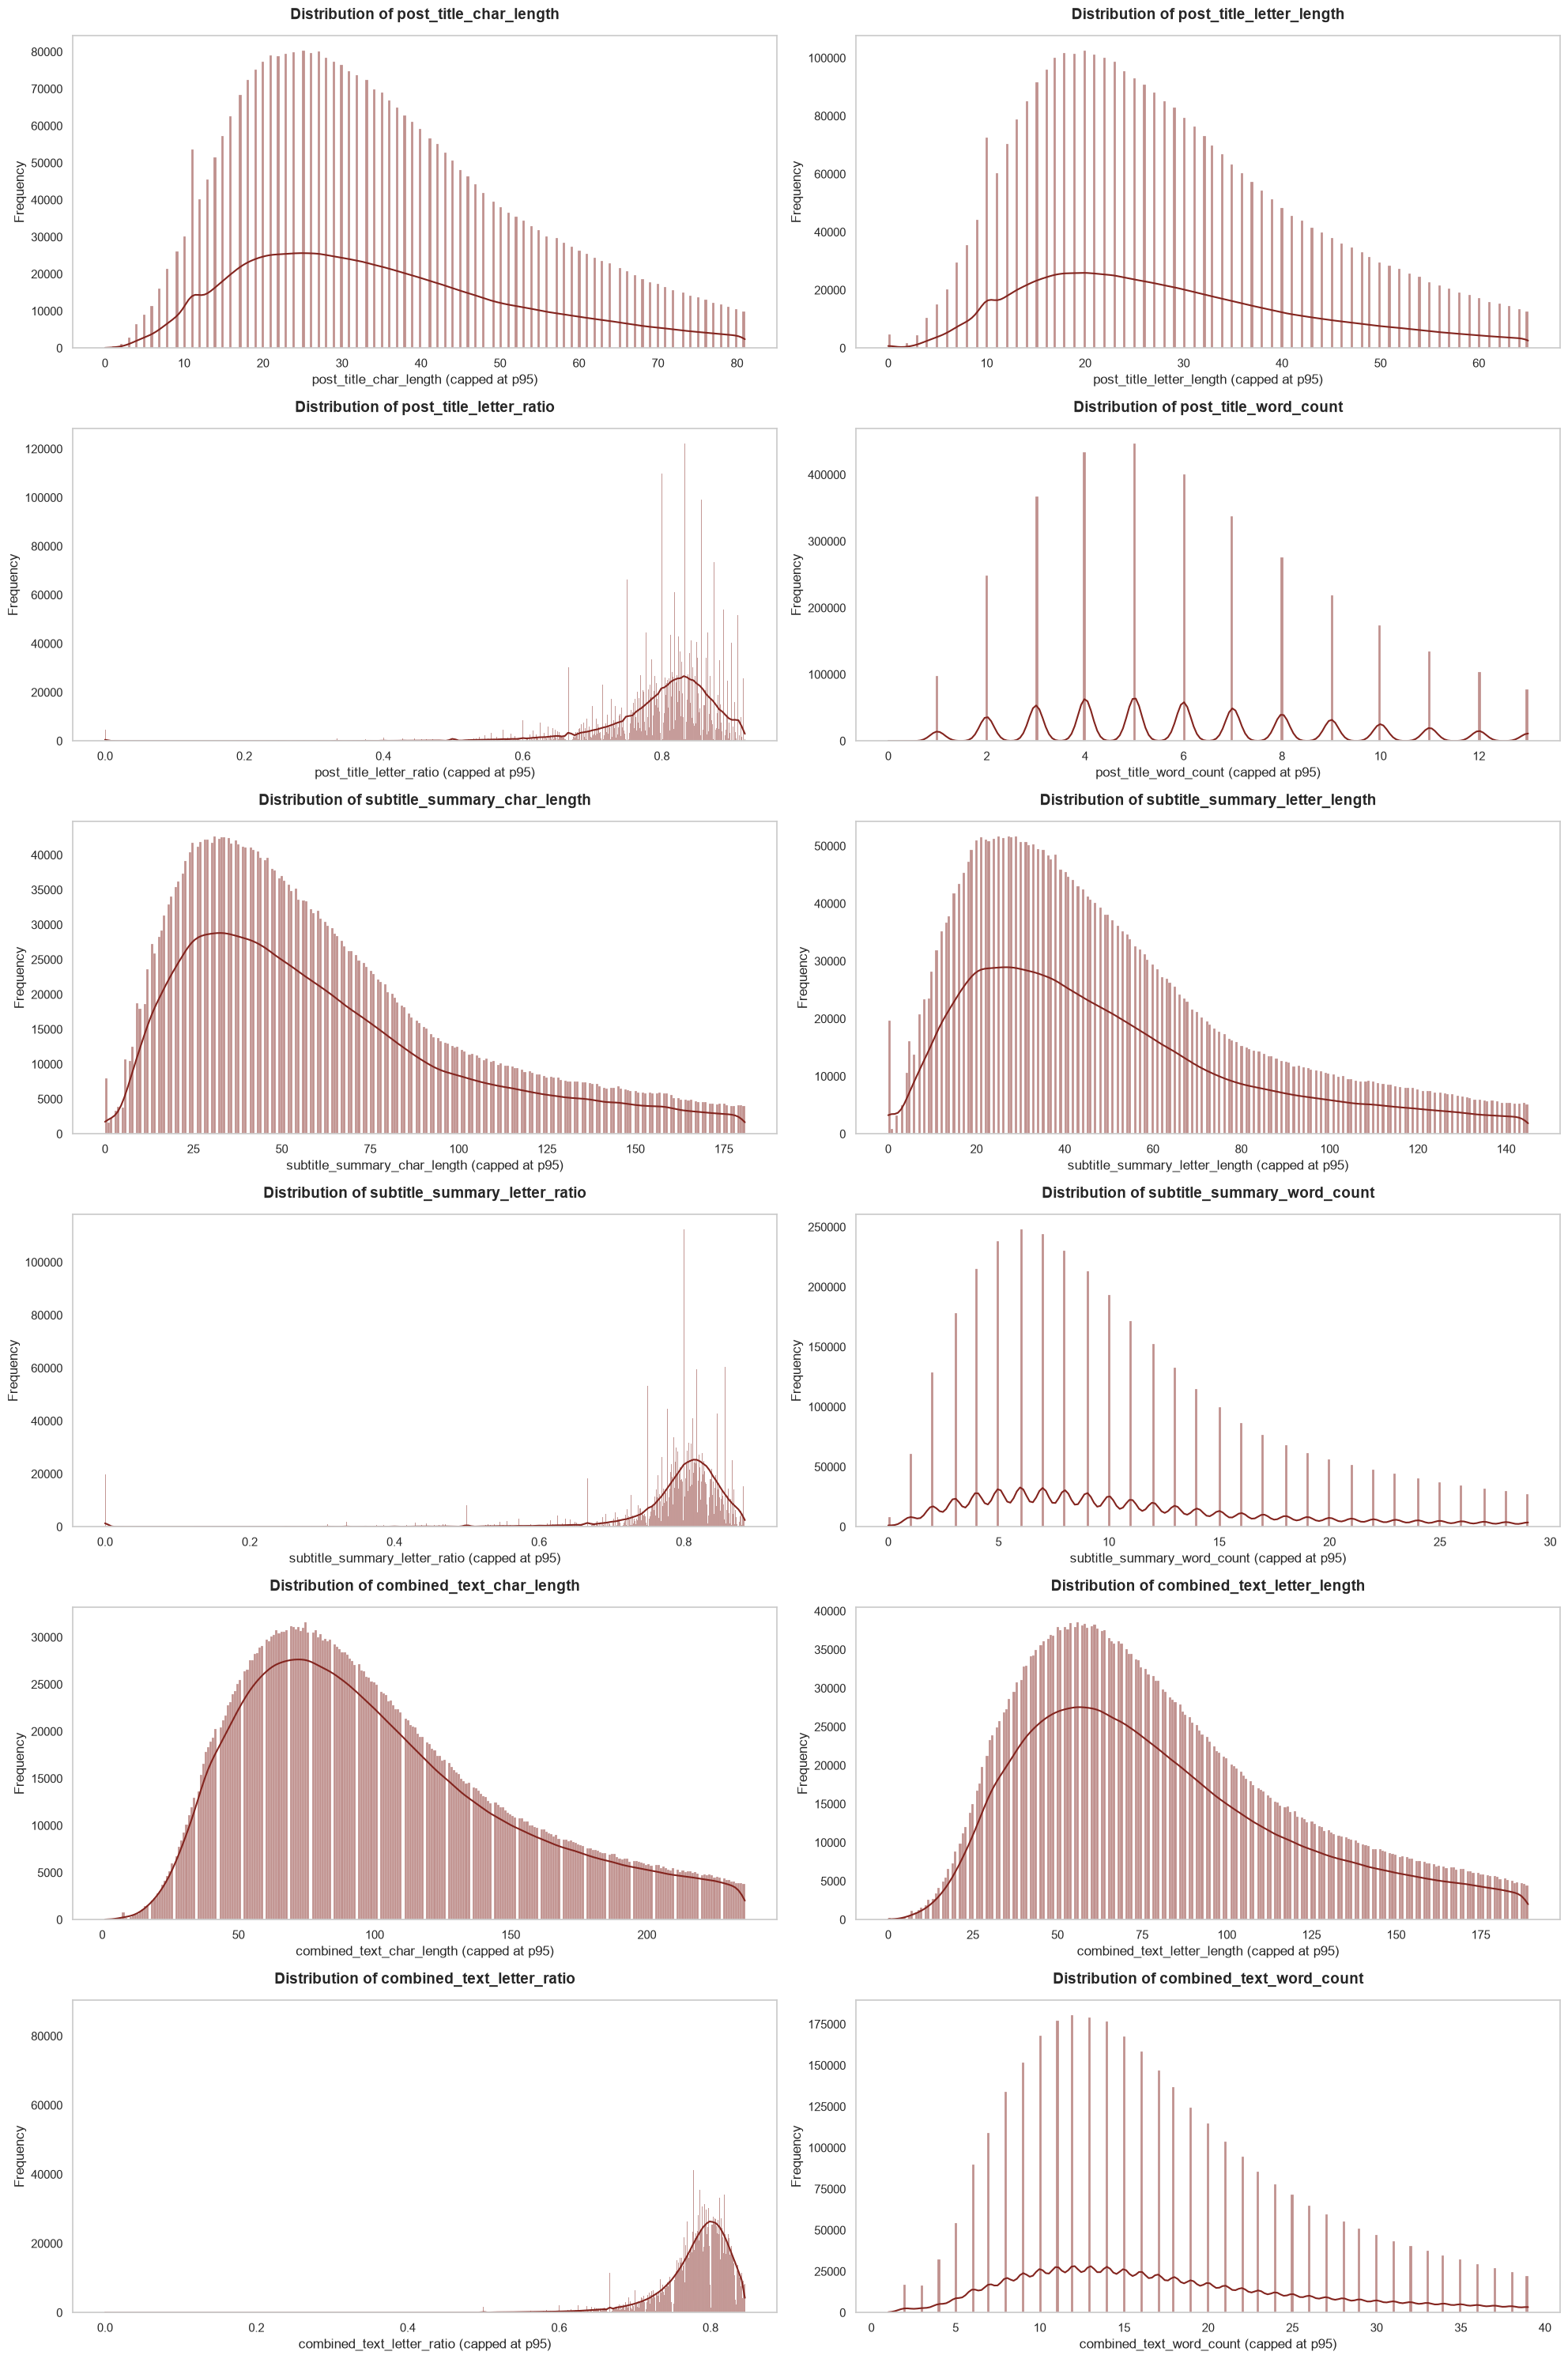

In [20]:
# For numeric columns - Plot the distribution of each numeric column, capped at the 95th percentile
num_cols = text_quality_df.select_dtypes(include='number').columns
total_plots = len(num_cols)

ncols = 2
nrows = math.ceil(total_plots / ncols)

fig, axes = apply_custom_theme(figsize=(20, nrows * 5), nrows=nrows, ncols=ncols)

for i, col in enumerate(num_cols):
    ax = axes[i]  
    sns.histplot(
        data=text_quality_df[(text_quality_df[col] < text_quality_df[col].quantile(0.95))], 
        x=col, 
        kde=True, 
        ax=ax
    )
    
    # Style only this specific grid coordinate section
    finalize_plot_layout(
        ax=ax,
        title=f"Distribution of {col}",
        xlabel=f"{col} (capped at p95)",
        ylabel="Frequency"  
    )
for j in range(total_plots, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [21]:
display(text_quality_df["combined_text_word_count"]
        .value_counts(normalize=True)
        .sort_index().reset_index(name="proportion")
        .assign(cumulative_proportion=lambda df: df["proportion"].cumsum()))
display(text_quality_df[(text_quality_df['combined_text_letter_ratio'] > 0.5) & 
                        (text_quality_df['combined_text_word_count'] <= 3)].head(50))

,combined_text_word_count,proportion,cumulative_proportion
0,1,0.000,0.000
1,2,0.005,0.005
2,3,0.005,0.010
3,4,0.009,0.019
4,5,0.015,0.034
...,...,...,...
2222,17751,0.000,1.000
2223,23787,0.000,1.000
2224,24442,0.000,1.000
2225,25799,0.000,1.000


,post_title,subtitle_summary,combined_text,post_title_post_title_decoded,post_title_char_length,post_title_letter_length,post_title_letter_ratio,post_title_is_letter_poor,post_title_word_count,post_title_has_html,...,subtitle_summary_has_emoji,combined_text_combined_text_decoded,combined_text_char_length,combined_text_letter_length,combined_text_letter_ratio,combined_text_is_letter_poor,combined_text_word_count,combined_text_has_html,combined_text_has_mojibake,combined_text_has_emoji
5,小孩的基金帳戶,&#20170;&#22825;&#36225;&#26202;&#19978;&#26377;&#31354;&#65292;&#25226;&#23567;&#2340...,小孩的基金帳戶. &#20170;&#22825;&#36225;&#26202;&#19978;&#26377;&#31354;&#65292;&#25226;&#235...,小孩的基金帳戶,7,7,1.000,False,1,False,...,False,小孩的基金帳戶. 今天趁晚上有空，把小孩阿哲剛開好的基富通戶頭設定好，設定三檔TISA基金，與0050連結基金，0050搭配低檔自動扣的功能。,71,56,0.789,False,2,True,False,False
166,HEARTBREAK COMEBACK,ZIKORA;,HEARTBREAK COMEBACK. ZIKORA;,HEARTBREAK COMEBACK,19,18,0.947,False,2,False,...,False,HEARTBREAK COMEBACK. ZIKORA;,28,24,0.857,False,3,False,False,False
204,Electrical Shepherd,"<div class=""captioned-image-container""><figure><a class=""image-link image2 is-viewable...","Electrical Shepherd. <div class=""captioned-image-container""><figure><a class=""image-li...",Electrical Shepherd,19,18,0.947,False,2,False,...,False,Electrical Shepherd.,20,18,0.900,False,2,False,False,False
252,6月15日双子座新月 ABC分析でビジネスを伸ばす,&#12469;&#12499;&#12450;&#12531;&#12364;&#25945;&#12360;&#12427;&#12289;&#27531;&#1237...,6月15日双子座新月 ABC分析でビジネスを伸ばす. &#12469;&#12499;&#12450;&#12531;&#12364;&#25945;&#12360;&#1...,6月15日双子座新月 ABC分析でビジネスを伸ばす,25,21,0.840,False,2,False,...,False,6月15日双子座新月 ABC分析でビジネスを伸ばす. サビアンが教える、残す枝と落とす枝の見極め方,49,42,0.857,False,3,True,False,False
362,コミュニティマネージャーSRKTKさんが教えてくれたNFTという結束,&#31532;&#20108;&#22238;PalClass&#12434;&#32066;&#12360;&#12390;,コミュニティマネージャーSRKTKさんが教えてくれたNFTという結束. &#31532;&#20108;&#22238;PalClass&#12434;&#32066;&#...,コミュニティマネージャーSRKTKさんが教えてくれたNFTという結束,34,34,1.000,False,1,False,...,False,コミュニティマネージャーSRKTKさんが教えてくれたNFTという結束. 第二回PalClassを終えて,51,49,0.961,False,2,True,False,False
472,開放島之家，我在想什麼，又收穫/給予了什麼？,&#21435;&#24180;9&#26376;&#65292;&#25105;&#22312;&#31038;&#20132;&#23186;&#39636;&#199...,開放島之家，我在想什麼，又收穫/給予了什麼？. &#21435;&#24180;9&#26376;&#65292;&#25105;&#22312;&#31038;&#201...,開放島之家，我在想什麼，又收穫/給予了什麼？,22,18,0.818,False,1,False,...,False,開放島之家，我在想什麼，又收穫/給予了什麼？. 去年9月，我在社交媒體上公佈了一則信息：,44,35,0.795,False,2,True,False,False
604,16金爱烂，当代贫穷书写指南,&#12304;&#20027;&#25773;&#30340;&#35805;&#12305; &#26412;&#26399;&#33410;&#30446;&#652...,16金爱烂，当代贫穷书写指南. &#12304;&#20027;&#25773;&#30340;&#35805;&#12305; &#26412;&#26399;&#334...,16金爱烂，当代贫穷书写指南,14,11,0.786,False,1,False,...,False,16金爱烂，当代贫穷书写指南. 【主播的话】 本期节目，读笨书关注金爱烂是如何书写贫穷的。我们选择了两个金爱烂的文本，一个是出自于《你的夏天还好吗》短篇集里的最后一篇《三十...,182,155,0.852,False,3,True,False,False
660,ワクワクは、始まる少し前にいる,&#32080;&#26524;&#12424;&#12426;&#12300;&#30452;&#21069;&#12398;&#20104;&#24863;&#1230...,ワクワクは、始まる少し前にいる. &#32080;&#26524;&#12424;&#12426;&#12300;&#30452;&#21069;&#12398;&#201...,ワクワクは、始まる少し前にいる,15,14,0.933,False,1,False,...,False,ワクワクは、始まる少し前にいる. 結果より「直前の予感」をデザインする｜ワクワクをつくる4つの入口・第1回,53,44,0.830,False,2,True,False,False
667,unmasked,a poem,unmasked. a poem,unmasked,8,8,1.000,False,1,False,...,False,unmasked. a poem,16,13,0.812,False,3,False,False,False
757,página 09,cair,página 09. cair,página 09,9,6,0.667,False,2,False,...,False,página 09. cair,15,10,0.667,False,3,False,False,False


**Observations**
- 16.2% of posts contain raw HTML entities in combined title and subtitle. 
- Some entities are emoji and words written as numbers (for example `&#128570;`). Decoded HTML entities before emoji check and text structural metrics calculation.
- About 0.2% of combined text are letter-poor (under half letters). 
- 4.2% of combined text contain emoji. No text has encoding damage (mojibake).
- About 1% of posts have three words or fewer once title and subtitle are combined. 

**Decisions** 
- Decode HTML entities and strip tags in both columns, join them as `title. subtitle`, and drop posts that are letter-poor or have fewer than four words.

## 7. Text: Duplicates, recurring titles and series

- Investigate different types of duplicates in the dataset.
- Including exact duplicates of publication, title and subtitle, potential recurring series with duplicate publication and title and duplicate titles/subtitles globally from substack template

In [22]:
# Display duplicate breakdown and show top duplicate entries
dup_summary = display_duplicate_breakdown(df, top_n=25)
display(dup_summary)


--- 1. Duplicate Article URLs ---
No duplicates found in this category.

--- 2. Exact Clones (Publication + Exact Title + Exact Subtitle) ---


,publication_domain,clean_title,clean_sub,Total Count
0,https://elliekrug.substack.com,Being Ellen,Advocacy with Heart,20
1,https://theaquinian.substack.com,The AQ Weekly,Welcome to the AQ Weekly.,20
2,https://damtoby.substack.com,Punish the Dead,A weekly comic from Toby Craig,20
3,https://kenroberts417455.substack.com,Live with Ken Roberts,A recording from Ken Roberts's live video,20
4,https://dcwritersroom.substack.com,Lit Life,A newsletter of the DC Writers Room,20
5,https://dijkshoorn.substack.com,Een jaar lang kijken naar hetzelfde schilderij,En iedere dag daar iets over schrijven,20
6,https://doyles.substack.com,Hamish McKenzie Killed Someone,"His delight in the murder was profound, and intensely sexual.",20
7,https://eduemma.substack.com,Emma's educational round-up,A weekly/fortnightly insight into developments within the realm of education.,20
8,https://emilykarst.substack.com,Saturday Bloom ☁️,"the bites, listening, outfits, orders, and mindset that made my week joyful.",20
9,https://lauraperkinsmindfulliving.substack.com,The Daily Muse,"Your Practice Companion for Mindful Living. - With love, Laura",20



--- 3. Exact Clones After Taking Series into Account (Publication + Exact Title + Exact Subtitle) ---


,publication_domain,series_title_key,series_sub_key,Total Count
0,https://zwierzecisie.substack.com,tygodnik zwierzę ci się 0,a w nim,20
1,https://neuebellona.substack.com,neue bellona,gerald hensels geo und sicherheitspolitik leseliste,20
2,https://lasentinelledu53.substack.com,la sentinelle du 0 n 0,le média local qui donne le smile aux mayennais pour s informer vite fait et sans dépr...,20
3,https://cafinalaudit.substack.com,ca final audit chapter 0 class 0 part 0,in this podcast we will revise few topics of chapter 0,20
4,https://toddbot.substack.com,the poet,a daily comic strip by todd webb,20
5,https://latinamericaimpactinvesting.substack.com,latin america impact investing 0,latin america impact investing towards a positive impacting economy,20
6,https://laurabelmonte.substack.com,the full belmonte 0 0 0,blacksburg va,20
7,https://lauraperkinsmindfulliving.substack.com,the daily muse,your practice companion for mindful living with love laura,20
8,https://buwheelockspace.substack.com,the weekly recap,news and updates from across bu wheelock space this week,20
9,https://bucurestifm.substack.com,capitala în inbox ul tău 0,newsletter bucurești fm,20



--- 4. Recurring Publication Titles (Same Titles within a Publication) ---


,publication_domain,clean_title,Total Count
0,https://damtoby.substack.com,Punish the Dead,20
1,https://manifestyouraura.substack.com,"Tea, Tarot, + Tidbits",20
2,https://manleymacro.substack.com,The Manley Macro Memo,20
3,https://look.substack.com,History in Pictures,20
4,https://theyogasequencehub.substack.com,Sequence of the week,20
5,https://jzschafer.substack.com,(a trifle),20
6,https://tedlevin.substack.com,Another Morning in Paradise,20
7,https://gregleichner.substack.com,"Memoir, from just outside the box",20
8,https://gregpeck.substack.com,The Widower,20
9,https://brianosh.substack.com,Signs,20


... (7 outputs left out)

,clean_sub,Total Count
0,Read more,3859
1,a poem,1288
2,A private space for us to converse and connect,1145
3,Introduction,1044
4,A poem,965
5,1.,898
6,A Poem,727
7,Hello!,609
8,Part 1,497
9,"Hi everyone,",494



--- 9. Duplicated URL Slugs Globally ---


,url_slug,Total Count
0,coming-soon,28788
1,join-my-new-subscriber-chat,890
2,welcome,641
3,NaN,606
4,happy-new-year,378
5,start-here,332
6,thank-you,295
7,ai,253
8,1,241
9,whats-in-a-name,218


,metric,rows,pct_share
0,1. Duplicate Article URLs,0,0.000
1,2. Exact Clones (Publication + Exact Title + Exact Subtitle),13187,0.375
2,3. Exact Clones After Taking Series into Account (Publication + Exact Title + Exact Su...,61166,1.741
3,4. Recurring Publication Titles (Same Titles within a Publication),59408,1.691
4,5. Recurring Publication Titles After Taking Series into Account (Same Titles within a...,208474,5.933
5,6. Shared Title + Subtitle Patterns (Across Different Publications),18669,0.531
6,7. Duplicated Titles Globally,191640,5.454
7,8. Duplicated Subtitles Globally,243766,6.937
8,9. Duplicated URL Slugs Globally,252188,7.177


**Observations**
- No duplicate URLs, and under 0.4% exact clones (same publication, title and subtitle). These are mostly recurring editions.
- Recurring editions often have numbered series. Turning numbers into a placeholder (`Chapter 33` and `#133` both become `0`) raises the share of exact clones from 0.38% to 1.74% and recurring titles within a publication from 1.7% to 5.9%.
- Generic titles, subtitles and URL slugs are reused across many publications, at 5 to 7% of posts: 
    - Announcement Type: `coming soon`
    - Greetings Type: `dear friends,`, `hi everyone,`, `hello!`
    - Recruitment Type: `join my new subscriber chat`, `join me on notes`, `join-my-new-subscriber-chat`

**Decisions** 
- Drop duplicates of the same publication and the same *normalised title plus subtitle* (61,166 posts, 1.7%).
- Recurring titles from same publication with **different subtitles** are kept: about 4% of posts (5.9% minus the 1.7% removed: the checks overlap, so this is approximate). 
- Remove generic and low-infomation posts such as announcement, greetings and recruitment post type.



#### For validation: look up publication, title and article url
- Fill in any of the four strings to list matching posts

In [23]:
# Check for specific publication, title, and subtitle combination
check_pub = ""
check_title = ""
check_subtitle = ""
check_url_slug = r"/p/"

check_df = (df["publication_domain"].str.contains(check_pub)) & \
           (df["post_title"].str.contains(check_title))& \
           (df["subtitle_summary"].str.contains(check_subtitle)) & \
           (~df["article_url"].str.contains(check_url_slug))
display(safe_view(df, n=50, mask=check_df, seed=SEED).sort_values("publish_date"))

,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category,publish_year
1104261,https://1debbie.substack.com,No title,https://1debbie.substack.com/publish/post/149173000,2024-09-20 19:28:47,,8,2,0,General & Uncategorized,2024
3252049,https://1debbie.substack.com,No title,https://1debbie.substack.com/publish/post/149173006,2024-09-20 19:28:51,,8,2,0,General & Uncategorized,2024
3277608,https://mirandadevine1.substack.com,No title,https://mirandadevine1.substack.com/publish/post/149919902,2024-10-07 14:07:01,,8,2,0,General & Uncategorized,2024
2757814,https://stephenthair.substack.com,No title,https://stephenthair.substack.com/publish/post/151257897,2024-11-06 07:56:37,,8,2,0,Technology & AI,2024
2287854,https://bronwenkeyesbevan.substack.com,No title,https://bronwenkeyesbevan.substack.com/publish/post/153467766,2024-12-21 21:48:12,,8,2,0,General & Uncategorized,2024
1610223,https://aaronazza.substack.com,No title,https://aaronazza.substack.com/publish/post/154089409,2025-01-03 17:35:10,,8,2,0,General & Uncategorized,2025
2825243,https://aaronazza.substack.com,No title,https://aaronazza.substack.com/publish/post/154304364,2025-01-07 00:11:37,,8,2,0,General & Uncategorized,2025
2567411,https://thenoblepbk52.substack.com,No title,https://thenoblepbk52.substack.com/publish/post/154419783,2025-01-08 19:56:40,,8,2,0,General & Uncategorized,2025
1011951,https://me1ancholic.substack.com,No title,https://me1ancholic.substack.com/publish/post/155603028,2025-01-24 08:40:19,,8,2,0,General & Uncategorized,2025
783981,https://timsmith733.substack.com,No title,https://timsmith733.substack.com/publish/post/156261453,2025-02-01 20:18:50,,8,2,0,General & Uncategorized,2025


## 8. Text: Language and Script

- The dataset includes non-English content, which may affect the subsequent topic modelling analysis. 
- Used `fasttext` for language detection: Efficient for large-scale text data and and outperformed `langdetect` in a sample tests.

In [24]:
%%time
language_df = language_summary(
    fasttext_model_path=LANGUAGE_DETECTION_MODEL_PATH, 
    df=df,
    title_col="post_title",
    sub_col="subtitle_summary"
)


--- Confidence Score Distribution ---


count   3,513,881.000
mean            0.854
std             0.153
min             0.035
5%              0.521
10%             0.650
25%             0.804
50%             0.906
75%             0.961
90%             0.985
95%             0.993
max             1.000
Name: confidence, dtype: float64


--- Script Shares Profile ---


,script,size,pct_share
23,LATIN,3466693,98.657
6,CJK,17502,0.498
0,ARABIC,15033,0.428
7,CYRILLIC,4585,0.130
17,HANGUL,1748,0.050
13,GREEK,1731,0.049
21,KATAKANA,1506,0.043
19,HIRAGANA,1180,0.034
18,HEBREW,1084,0.031
8,DEVANAGARI,649,0.018



--- Language Shares Profile ---


,language,size,pct_share
35,en,2952633,84.028
37,es,140179,3.989
109,pt,110769,3.152
42,fr,71255,2.028
64,it,61129,1.740
30,de,20953,0.596
136,tr,17267,0.491
99,nl,16463,0.469
4,ar,14859,0.423
65,ja,14293,0.407



--- Alignment Metrics & Anomalies ---
Mismatch - English language but not LATIN script: 480 rows, 0.014%


,text,clean_text,script,language,confidence
977,The fear of failure as a poet. &#119827;&#119841;&#119838; &#119839;&#119838;&#119834;...,The fear of failure as a poet. 𝐓𝐡𝐞 𝐟𝐞𝐚𝐫 𝐨𝐟 𝐟𝐚𝐢𝐥𝐮𝐫𝐞 𝐚𝐬 𝐚 𝐩𝐨𝐞𝐭 𝐨𝐫 𝐰𝐫𝐢𝐭𝐞𝐫 𝐡𝐚𝐮𝐧𝐭𝐬 𝐮𝐬 𝐚𝐥𝐥.,MATHEMATICAL,en,0.435
8713,#42. ~~~~~~,#42. ~~~~~~,NONE,en,0.300
14720,𝐒𝐞𝐥𝐥 𝐢𝐧 𝐌𝐚𝐲 𝐚𝐧𝐝 𝐠𝐨 𝐚𝐰𝐚𝐲? 𝐈 𝐝𝐨𝐧’𝐭 𝐭𝐡𝐢𝐧𝐤 𝐬𝐨!. Riding the software horse&#8230;,𝐒𝐞𝐥𝐥 𝐢𝐧 𝐌𝐚𝐲 𝐚𝐧𝐝 𝐠𝐨 𝐚𝐰𝐚𝐲? 𝐈 𝐝𝐨𝐧’𝐭 𝐭𝐡𝐢𝐧𝐤 𝐬𝐨!. Riding the software horse…,MATHEMATICAL,en,0.248
30608,Mourning and living. [ &#120456;&#120472;&#120478; &#120480;&#120466;&#120469;&#120469...,"Mourning and living. [ 𝚈𝚘𝚞 𝚠𝚒𝚕𝚕 𝚊𝚕𝚠𝚊𝚢𝚜 𝚋𝚎 𝚊𝚋𝚕𝚎 𝚝𝚘 𝚛𝚎𝚊𝚍 𝚖𝚎 𝚏𝚘𝚛 𝚏𝚛𝚎𝚎, 𝚋𝚞𝚝 𝚠𝚛𝚒𝚝𝚒𝚗𝚐 𝚒𝚜 𝚑𝚘𝚠...",MATHEMATICAL,en,0.462
47003,~. <p></p>,~.,NONE,en,0.214
48371,蜜月. 2026 &#38568;&#31558; #1,蜜月. 2026 隨筆 #1,CJK,en,0.519
49203,"""أوطان"". <p></p>","""أوطان"".",ARABIC,en,0.195
55237,𝑾𝒉𝒂𝒕 𝑰𝒇 𝑨𝒍𝒍𝒂𝒉 𝑾𝒂𝒔 𝑵𝒐𝒕 𝑻𝒉𝒆 𝑶𝒏𝒆 𝒀𝒐𝒖 𝑾𝒆𝒓𝒆 𝑺𝒆𝒆𝒌𝒊𝒏𝒈?. The question behind every deed done i...,𝑾𝒉𝒂𝒕 𝑰𝒇 𝑨𝒍𝒍𝒂𝒉 𝑾𝒂𝒔 𝑵𝒐𝒕 𝑻𝒉𝒆 𝑶𝒏𝒆 𝒀𝒐𝒖 𝑾𝒆𝒓𝒆 𝑺𝒆𝒆𝒌𝒊𝒏𝒈?. The question behind every deed done i...,MATHEMATICAL,en,0.549
66112,🆕🆓🌿🔜👀. &#128339;&#128336;&#128337;&#128338;,🆕🆓🌿🔜👀. 🕓🕐🕑🕒,NONE,en,0.214
67217,𝗚𝗜𝗢𝗩𝗔𝗡𝗡𝗜 𝗙𝗘𝗥𝗥𝗜. 𝗤𝗨𝗘𝗟𝗟𝗔 𝗧𝗥𝗔𝗖𝗖𝗜𝗔 𝗦𝗨𝗟 𝗠𝗨𝗥𝗢 𝗘𝗥𝗔 𝗚𝗜𝗔̀ 𝗟𝗜̀. &#120237;&#120254;&#120261; 2010...,𝗚𝗜𝗢𝗩𝗔𝗡𝗡𝗜 𝗙𝗘𝗥𝗥𝗜. 𝗤𝗨𝗘𝗟𝗟𝗔 𝗧𝗥𝗔𝗖𝗖𝗜𝗔 𝗦𝗨𝗟 𝗠𝗨𝗥𝗢 𝗘𝗥𝗔 𝗚𝗜𝗔̀ 𝗟𝗜̀. 𝖭𝖾𝗅 2010 𝗊𝗎𝖺𝗅𝖼𝗎𝗇𝗈 𝖿𝗈𝗍𝗈𝗀𝗋𝖺𝖿𝗈̀ 𝗎𝗇𝖺...,MATHEMATICAL,en,0.328


Filtered LATIN/MATHEMATICAL English content: 2952380 rows, 84.02%
Filtered LATIN/MATHEMATICAL English content with confidence > 0.1: 2952177 rows, 84.015%
CPU times: user 58.1 s, sys: 1.23 s, total: 59.3 s
Wall time: 59.6 s


In [25]:
# Review confidence scores cut-off for English language texts 
language_df[(language_df["language"] == "en") & 
            language_df['confidence'].between(0.1, 0.3)].sort_values(by="confidence", ascending=True).head(50)

,text,clean_text,script,language,confidence
698178,"IGA RAALI AHOW, GACANTEYDU MA GACAN QAADDO NIN KHIYAANEY WADDANKIISA.. Mid ka mid ah d...","IGA RAALI AHOW, GACANTEYDU MA GACAN QAADDO NIN KHIYAANEY WADDANKIISA.. Mid ka mid ah d...",LATIN,en,0.100
1718150,When I Heard the Internet Guru. With apologies to Walt Whitman,When I Heard the Internet Guru. With apologies to Walt Whitman,LATIN,en,0.100
1791479,"Jonah 3:1-10 // What Repentance Looks Like. Jonah, Part III","Jonah 3:1-10 // What Repentance Looks Like. Jonah, Part III",LATIN,en,0.100
106938,Maraykanka Oo Dagaalka Ku Biiray Iyo Iiraan Oo Garaacday Xarumo Kuyaal Tal-abiib.. Dow...,Maraykanka Oo Dagaalka Ku Biiray Iyo Iiraan Oo Garaacday Xarumo Kuyaal Tal-abiib.. Dow...,LATIN,en,0.100
3376053,DAREEN KA SAMAYSAN CIIL:. Waa nolol qallafsan oo naxariista dhalanka ah layska tuugo.,DAREEN KA SAMAYSAN CIIL:. Waa nolol qallafsan oo naxariista dhalanka ah layska tuugo.,LATIN,en,0.100
1519158,LAKE AMERICA?. GULF OF AMERICA?,LAKE AMERICA?. GULF OF AMERICA?,LATIN,en,0.100
1126218,?FORTRESS NORTH AMERICA?. ?FORTRESS NORTH AMERICA?,?FORTRESS NORTH AMERICA?. ?FORTRESS NORTH AMERICA?,LATIN,en,0.100
312203,Forever Man -- Chapter 69. A New Name,Forever Man -- Chapter 69. A New Name,LATIN,en,0.100
103267,Session 53 // 17.11.2025. Keith Tippett & Louis Moholo &#8211; No Gossip (1982),Session 53 // 17.11.2025. Keith Tippett & Louis Moholo – No Gossip (1982),LATIN,en,0.101
2063940,XABSIGA SHAASHADA IYO XORIYADDA NAFTA/QALBIGA. Marar kale duwan ma is-weydiisay sababt...,XABSIGA SHAASHADA IYO XORIYADDA NAFTA/QALBIGA. Marar kale duwan ma is-weydiisay sababt...,LATIN,en,0.101


**Observations**
- Latin script is 98.7%, so script alone cannot separate English from Spanish (4.0%), Portuguese (3.2%), French (2.0%) or Italian (1.7%).
- 84% of posts are English detected using fastText. 
- On average, the model has a confident score of 0.85 in its language predictions 
    - Using **script type** as an additional language validation as fastText is less confident on short text. 
    - Reading English predictions between 0.1 and 0.3 confidence, most were fine. 
    - Some English-labelled texts were written in fancy Unicode letters (a mathematical-alphabet bold style), or were only symbols and digits.

**Decisions** 
- Keep posts that are English and in Latin or mathematical-alphabet script, with confidence above 0.1. This removes 16% of posts, the largest cut in the pipeline.

## 9. Text: Low-Information posts (Announcement, Greetings and Recruitment related posts)

- Lenient Exclusions: Keywords (like coming soon, join my ..., join us ...) and placeholder slugs (like /p/coming-soon) act as a baseline negative filter to remove low-information announcements and recruitment articles.
- To avoid accidentally removing deep-dive articles (e.g., an article discussing the cultural impact of Zoom or an in-depth community thread), these filters are intentionally lenient. 
- Consequently, some edge-case promotional or placeholder articles may still slip into the dataset.


In [26]:
low_info = low_information_posts_summary(df, sample=25, seed=SEED)
display(low_info["summary"])
print("Sample Keyword Filtered")
display(low_info["sample-keyword-filtered"])
print("Sample Slug Filtered")
display(low_info["sample-slug-filtered"])
print("Sample Empty Slug")
display(low_info["sample-empty-slug"])

,metric,rows,pct_share
0,keyword-flagged low-information posts (announcement and recruitment),24182,0.688
1,slug-flagged low-information posts (announcement and recruitment),32558,0.927
2,empty-slug posts,606,0.017
3,either,34871,0.992


Sample Keyword Filtered


,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category,publish_year
2518991,https://highfrequencybeing.substack.com,Coming soon,https://highfrequencybeing.substack.com/p/coming-soon,2026-02-03 07:17:59,This is High's Substack.,11,2,1,General & Uncategorized,2026
1679601,https://mscottweiss.substack.com,Coming soon,https://mscottweiss.substack.com/p/coming-soon,2023-10-15 11:57:32,This is Mike's Substack.,11,2,1,General & Uncategorized,2023
2338117,https://tonyliebert.substack.com,Coming soon,https://tonyliebert.substack.com/p/coming-soon,2025-03-22 15:13:35,This is Tony's Substack.,11,2,1,General & Uncategorized,2025
1886691,https://ashleygarcialezcano.substack.com,Coming soon,https://ashleygarcialezcano.substack.com/p/coming-soon,2025-06-19 05:17:07,This is Ashley's Substack.,11,2,1,General & Uncategorized,2025
3203677,https://buttonpoetry.substack.com,Coming soon,https://buttonpoetry.substack.com/p/coming-soon,2025-06-05 13:53:19,This is Button's Substack.,11,2,1,"Culture, Arts & Literature",2025
3176705,https://organizedpeople.substack.com,Join Us: Breaking the Code — Lessons from Hungary,https://organizedpeople.substack.com/p/join-us-breaking-the-code-lessons,2026-05-12 16:06:05,What can the U.S. and the world learn from the defeat of Viktor Orb&#225;n's 16-year a...,49,9,1,Technology & AI,2026
2646195,https://yourhomeschoolcompanion.substack.com,Coming soon,https://yourhomeschoolcompanion.substack.com/p/coming-soon,2025-01-30 09:24:21,This is Family Faith Legacy.,11,2,1,Technology & AI,2025
2117074,https://phala.substack.com,Phala Newsletter #2,https://phala.substack.com/p/phala-newsletter-2,2020-10-07 08:58:14,Testnet PoC-3 (and its incentive program) coming soon &#128075;,19,3,1,Politics & News,2020
524916,https://spacecrypto.substack.com,Coming soon,https://spacecrypto.substack.com/p/coming-soon,2022-01-05 13:01:20,"This is SpaceCrypto's Newsletter, a newsletter about SpaceCrypto game official blog.",11,2,1,Finance & Crypto,2022
3404768,https://weshouldbeintherapy.substack.com,Trailer: Holiday Grief & The Empty Chair (Coming Soon),https://weshouldbeintherapy.substack.com/p/trailer-holiday-grief-survival-guide,2025-12-20 18:04:37,"Why we are hiding in the guest room, feeding the ancestors, and rewriting the rules fo...",54,9,1,Technology & AI,2025


Sample Slug Filtered


,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category,publish_year
3456577,https://thefictionally.substack.com,Join my new subscriber chat,https://thefictionally.substack.com/p/join-my-new-subscriber-chat,2026-08-12 22:47:36,A private space for us to converse and connect,27,5,1,"Culture, Arts & Literature",2026
1108968,https://thefieldwire.substack.com,Research Jobs in Earth and Environmental Sciences,https://thefieldwire.substack.com/p/welcome,2022-08-06 23:57:49,"Get fully-funded research position (Masters, PhDs, PostDocs etc.) directly in your inbox.",49,7,1,Finance & Crypto,2022
697379,https://troylatter.substack.com,Coming soon,https://troylatter.substack.com/p/coming-soon,2025-01-04 22:08:45,This is Troy's Substack.,11,2,1,General & Uncategorized,2025
615258,https://treasa.substack.com,Coming soon,https://treasa.substack.com/p/coming-soon,2023-01-01 15:59:12,"This is beyond the map, a newsletter about new explorations in a time of change .",11,2,1,Politics & News,2023
2944088,https://urbanrenewal.substack.com,Coming soon,https://urbanrenewal.substack.com/p/coming-soon,2023-05-15 13:21:56,This is Researching Urban Renewal.,11,2,1,Science & Environment,2023
1931677,https://poetbear.substack.com,Coming soon,https://poetbear.substack.com/p/coming-soon,2025-01-06 18:32:12,This is Poetbear's Substack.,11,2,1,General & Uncategorized,2025
2369570,https://rampantse.substack.com,Coming soon,https://rampantse.substack.com/p/coming-soon,2025-01-13 20:01:06,This is Rampant's Substack.,11,2,1,General & Uncategorized,2025
2359487,https://pierrepoilievre.substack.com,Coming soon,https://pierrepoilievre.substack.com/p/coming-soon,2025-01-26 17:41:31,This is Pierre Poilievre's Substack.,11,2,1,General & Uncategorized,2025
21740,https://arianapierce.substack.com,Join my new subscriber chat,https://arianapierce.substack.com/p/join-my-new-subscriber-chat,2026-07-01 04:53:55,"A private space for us to converse, connect and share GOOD NEWS!",27,5,1,Politics & News,2026
2925101,https://pamcake.substack.com,The Hottest Gossip About Pamcake,https://pamcake.substack.com/p/coming-soon,2021-01-20 04:15:15,"Welcome to Pamcake (Newsletter Type) by me, Pamcake and Mochi.",32,5,1,Politics & News,2021


Sample Empty Slug


,publication_domain,post_title,article_url,publish_date,subtitle_summary,title_char_length,title_word_count,has_subtitle,category,publish_year
3260922,https://muxsinmacalinmaxamedmacalin.substack.com,No title,https://muxsinmacalinmaxamedmacalin.substack.com/publish/post/170157180,2025-08-05 08:00:31,,8,2,0,General & Uncategorized,2025
1610223,https://aaronazza.substack.com,No title,https://aaronazza.substack.com/publish/post/154089409,2025-01-03 17:35:10,,8,2,0,General & Uncategorized,2025
487067,https://nimetece.substack.com,No title,https://nimetece.substack.com/publish/post/157019248,2025-02-12 20:14:57,,8,2,0,General & Uncategorized,2025
497596,https://vrilimperium1.substack.com,No title,https://vrilimperium1.substack.com/publish/post/186704275,2026-02-03 05:30:23,,8,2,0,General & Uncategorized,2026
975880,https://allamericanjane.substack.com,No title,https://allamericanjane.substack.com/publish/post/157179961,2025-02-15 02:38:08,,8,2,0,General & Uncategorized,2025
3343988,https://carlosmamukycastro.substack.com,No title,https://carlosmamukycastro.substack.com/publish/post/159100213,2025-03-14 23:08:19,,8,2,0,General & Uncategorized,2025
53373,https://kahvelervedusunceler.substack.com,No title,https://kahvelervedusunceler.substack.com/publish/post/166222801,2025-06-18 08:07:24,,8,2,0,General & Uncategorized,2025
748931,https://manny224414.substack.com,No title,https://manny224414.substack.com/publish/post/159098080,2025-03-14 22:32:11,,8,2,0,General & Uncategorized,2025
2569339,https://limcio.substack.com,No title,https://limcio.substack.com/publish/post/167005597,2025-06-27 21:04:12,,8,2,0,General & Uncategorized,2025
528596,https://heron96.substack.com,No title,https://heron96.substack.com/publish/post/191501720,2026-03-19 17:42:12,,8,2,0,General & Uncategorized,2026


**Observations** 
- Flags for "coming soon", "join my..." and welcome-style URL slugs catch about 1% of posts (keyword 0.69%, slug 0.93%, no `/p/` URL 0.02%). 
- A few posts with no `/p/` URL are titled "No title", which marks invalid links.

**Decisions** 
- Drop flagged posts (34,871 after deduplication, 1%). At this dataset size, it is better to risk a few false positives than to leave low-info placeholder text in the corpus.
- To remove URL slugs that does not follow the `/p/` pattern.

## 10. Findings and decisions

| Topic | Observations | Decisions | Posts removed |
|---|---|---|---|
| Dates | 82% of posts are from 2025 to 2026, 878 posts dated before launch | Start from 2018-01-01 | 965 |
| `category` | Rule-based, with visible mislabels | Not using as ground truth | 0 |
| Publications | Capped at 50 by the collection, low Gini by design | No cap | 0 |
| Language | 84% English, fastText is less confidenct on short text | English with confidence above 0.1 and Latin or Mathematical script | 561,604 |
| Duplicates and Series | Normalising for edition and series variations increases exact publication, title and subtitles duplicates from 0.4% to 1.7%. About 4% recurring titles with new subtitles remain | Drop repeats of the same normalised title plus subtitle in a publication | 50,390 |
| Low-Info Posts (Annoucement and Recruitment) | About 1% flagged from using lenient keyword and URL slug exclusion rules | Drop flagged posts | 32,150 |
| Short or Letter-poor text | About 1% of posts have three words or fewer | Drop letter-poor posts and posts under 4 words | 14,125 |

**Result.** 2,854,647 of 3,513,881 posts remain (81.2%).

## 11. The cleaning pipeline

- The decisions above, in one function.
- `return_funnel=True` also returns the row counts after each step, which the Streamlit app draws.

In [27]:
df = load_raw(RAW_DATA_PATH/RAW_FILE_NAME)

In [28]:
from substack_topics.data.clean import preprocess_pipeline
# Cleaning pipeline
    # Filter dates
    # Nothing for article categories
    # Nothing for publication concentration (as the distribution is relatively balanced & already capped at 50)
    # Clean and unescape HTML in the post title and subtitle summary columns
    # Combine the cleaned post title and subtitle summary into a single text column
    # Filter for English language above 0.1 confidence score and Latin or Mathematical script
    # Drop exact text duplicates from same publication, including Recurring titles and Series
    # Drop low-information posts (Announcement and Recruitment related posts)
    # Drop short or letter-poor text

preprocessed_df, funnel_df = preprocess_pipeline(
    df=df,
    min_date="2018-01-01",
    max_date="2026-12-31",
    fasttext_model_path=LANGUAGE_DETECTION_MODEL_PATH,
    return_funnel=True,
)
display(safe_view(preprocessed_df, cols=[c for c in preprocessed_df.columns if c != "author_name"], n=20, seed=SEED))

INFO:substack_topics.data.clean:Initial date filter applied: 2018-01-01 <= post_date <= 2026-12-31
INFO:substack_topics.data.clean:[Date Filter] Dropped 965 rows (0.03%) | Remaining 3,512,916 rows (99.97%)
INFO:substack_topics.data.clean:[Language & Script Filter] Dropped 561,604 rows (15.99%) | Remaining 2,951,312 rows (84.01%)
INFO:substack_topics.data.clean:[Series Deduplication] Dropped 50,390 rows (1.71%) | Remaining 2,900,922 rows (98.29%)
INFO:substack_topics.data.clean:[Low-Information Post (Announcement and Recruitment) Filtering] Dropped 32,150 rows (1.11%) | Remaining 2,868,772 rows (98.89%)
INFO:substack_topics.data.clean:[Text Quality Filtering] Dropped 14,125 rows (0.49%) | Remaining 2,854,647 rows (99.51%)
INFO:substack_topics.data.clean:Pipeline Complete. Retained 2854647 (81.24%) out of 3513881 original rows.


,article_url,publication_domain,category,post_title,subtitle_summary,publish_date,publish_year,text_col,series_key
3117226,https://readtedium.substack.com/p/plastic-lemon-design-history,https://readtedium.substack.com,Food & Travel,Consider The Plastic Lemon 🍋,"The plastic lemon is one of the best-known kitsch objects, but its common nature creat...",2023-07-13 13:00:47,2023,Consider The Plastic Lemon 🍋. The plastic lemon is one of the best-known kitsch object...,consider the plastic lemon the plastic lemon is one of the best known kitsch objects b...
2928876,https://lovelylotus.substack.com/p/rest-isnt-a-guilty-pleasure-its-a,https://lovelylotus.substack.com,"Culture, Arts & Literature",Rest Isn’t a Guilty Pleasure. It’s a Power Move.,Burnout Series Part 21: Why the most powerful form of gratitude is giving yourself roo...,2025-11-27 12:03:15,2025,Rest Isn’t a Guilty Pleasure. It’s a Power Move.. Burnout Series Part 21: Why the most...,rest isn t a guilty pleasure it s a power move burnout series part 0 why the most powe...
1422781,https://johnbaer.substack.com/p/i-care-more-about-winning-than-ideological,https://johnbaer.substack.com,Politics & News,I Care More About Winning than Ideological Purity,"Barney Frank, one of my heroes and a very progressive Democrat, who died a month ago a...",2026-07-06 08:01:00,2026,"I Care More About Winning than Ideological Purity. Barney Frank, one of my heroes and ...",i care more about winning than ideological purity barney frank one of my heroes and a ...
2141418,https://tidesandtacos.substack.com/p/san-diego-non-alcoholic-cocktail-company,https://tidesandtacos.substack.com,Technology & AI,Herbal teas and drinking vinegars add creative edge to new wave of non-alcoholic cockt...,"When developing shrubs and tisane blends, Higher Vibration Tonics co-owners Lauren Luc...",2024-07-02 16:00:47,2024,Herbal teas and drinking vinegars add creative edge to new wave of non-alcoholic cockt...,herbal teas and drinking vinegars add creative edge to new wave of non alcoholic cockt...
248651,https://countryclarity.substack.com/p/listen-love-your-neighbor-is-the,https://countryclarity.substack.com,Personal Essays & Stories,"Listen, ""love your neighbor"" is the opposite of ""control your neighbor""","Steve's right: ""Christianity"" that prioritizes power and profit is not at all about Ch...",2025-03-29 00:25:45,2025,"Listen, ""love your neighbor"" is the opposite of ""control your neighbor"". Steve's right...",listen love your neighbor is the opposite of control your neighbor steve s right chris...
553600,https://jonathanfields.substack.com/p/why-most-advice-books-are-240-pages,https://jonathanfields.substack.com,"Culture, Arts & Literature",Why Most Advice Books Are 240 Pages (and Shouldn’t Be?),A wake-up call for authors and readers who want their lives back...,2025-06-29 12:17:09,2025,Why Most Advice Books Are 240 Pages (and Shouldn’t Be?). A wake-up call for authors an...,why most advice books are 0 pages and shouldn t be a wake up call for authors and read...
1572354,https://stefanbaciu.substack.com/p/one-touch,https://stefanbaciu.substack.com,Sports,One Touch,Confession in the Season of Uncovering: A Short Story in James Luo's Third Face Universe,2026-07-11 18:22:06,2026,One Touch. Confession in the Season of Uncovering: A Short Story in James Luo's Third ...,one touch confession in the season of uncovering a short story in james luo s third fa...
2301054,https://nadineartemisofficial.substack.com/p/the-perpetual-flush-rosacea-as-a,https://nadineartemisofficial.substack.com,Technology & AI,THE PERPETUAL FLUSH: ROSACEA AS A BIOLOGICAL SOS,"A comprehensive rosacea roadmap to reclaiming the skin, scalp, and ocular areas from D...",2026-07-13 20:13:09,2026,THE PERPETUAL FLUSH: ROSACEA AS A BIOLOGICAL SOS. A comprehensive rosacea roadmap to r...,the perpetual flush rosacea as a biological sos a comprehensive rosacea roadmap to rec...
3114849,https://happymondayash.substack.com/p/read-this-before-you-sit-

Save the cleaned corpus for the modelling notebooks.

In [29]:
# Save the preprocessed data to the interim data path

output_file_path = INTERIM_DATA_PATH/INTERIM_FILE_NAME
os.makedirs(INTERIM_DATA_PATH, exist_ok=True)
print(f"Saving preprocessed data to {output_file_path}")
preprocessed_df.to_parquet(output_file_path, index=False)

Saving preprocessed data to ../data/interim/substack_dataset/substack_processed.parquet


## 12. Export for the Streamlit app

- Small, aggregated summary tables only.
- **Anonymised sample posts (without author names or publication identifiers)** are exported, ensuring all artefacts are safe to commit.

In [30]:
import json

ARTEFACTS_PATH = Path("../artefacts/00_data_exploration/")
ARTEFACTS_PATH.mkdir(exist_ok=True)
print("Artefacts directory:", ARTEFACTS_PATH)

STEP_LABELS = {
    "Date Filter": "Date window (2018 onwards)",
    "Language & Script Filter": "English & Latin script",
    "Series Deduplication": "Recurring series / exact clones",
    "Low-Information Post (Announcement and Recruitment) Filtering": "Low information posts (Announcement and Recruitment)",
    "Text Quality Filtering": "Letter-poor or under 4 words",
}

Artefacts directory: ../artefacts/00_data_exploration


In [ ]:
# Export dataset structure and sample to the artifacts directory
# Tab 1. Overview & Tab 4. Publications
overview_path = ARTEFACTS_PATH / "corpus_overview.json"
q = by_publication_domain["posts_count"].describe()
language_mask = ((language_df.language == "en") & 
                 (language_df.confidence >= 0.1) & 
                 (language_df.script.isin(["LATIN", "MATHEMATICAL"])))
n_raw = len(df)

overview = {
    "raw_posts": n_raw,
    "publications": int(df["publication_domain"].nunique()),
    "authors": int(df["author_name"].nunique()),
    "categories": int(df["category"].nunique()),
    "date_min": str(df["publish_date"].min())[:10],
    "date_max": str(df["publish_date"].max())[:10],
    "launch_date": str(MIN_PLAUSIBLE_DATE)[:10],
    "posts_before_launch": int(early_dates_mask.sum()),
    "publications_before_launch": int(df.loc[early_dates_mask, "publication_domain"].nunique()),
    "posts_per_publication": {k: float(q[k]) for k in ["mean", "min", "25%", "50%", "75%", "max"]},
    "gini_posts_per_publication": round(gini(by_publication_domain["posts_count"]), 3),
    "gini_posts_per_category": round(gini(by_categories["posts_count"]), 3),
    "removed_by_language": int((~language_mask).sum()),
    "pct_removed_by_language": round(100 * (~language_mask).sum() / n_raw, 1),
    "cleaned_posts": int(len(preprocessed_df)),
    "pct_cleaned_posts": round(100 * len(preprocessed_df) / n_raw, 1),
}
overview_path.write_text(json.dumps(overview, indent=2), encoding="utf-8")

# Dataset structure & stats
dtypes_df = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.count().values,
    "null": df.isna().sum().values,
    "unique": df.nunique().values,
})
dtypes_df.to_csv(ARTEFACTS_PATH / "dataset_dtypes.csv", index=False)

(
    df.describe(include="all")
      .rename_axis("statistic")
      .reset_index()
      .to_csv(ARTEFACTS_PATH / "dataset_stats.csv", index=False)
)

# Remove sensitive information from sample data: publication domain, author names and article URLs. 
SAMPLE_N, MAX_CHARS = 50, 300
SENSITIVE_COLS = ["author_name", "article_url", "publication_domain"]

sample_df = (
    df.sample(min(SAMPLE_N, n_raw), random_state=SEED)
    .drop(columns=SENSITIVE_COLS, errors="ignore")
)
for column in ["post_title", "subtitle_summary"]:
    if column in sample_df.columns:
        sample_df[column] = sample_df[column].astype("string").str.slice(0, MAX_CHARS)

sample_df.to_csv(ARTEFACTS_PATH / "dataset_sample.csv", index=False)

In [32]:
# Export various data summaries and reports to the artifacts directory

# Tab 2. Dates
yearly_report_df.to_csv(ARTEFACTS_PATH / "yearly_posts.csv", index=False)

# Tab 3. Categories
by_categories.to_csv(ARTEFACTS_PATH / "categories.csv", index=False)
(
    by_year_category.pivot_table(
        index="publish_year",
        columns="category",
        values="post_count",
        aggfunc="sum",
        fill_value=0,
    )
    .reset_index()
    .to_csv(ARTEFACTS_PATH / "category_by_year.csv", index=False)
)


# Tab 5. Text Quality 
text_flag_summary.to_csv(ARTEFACTS_PATH / "text_quality_flags.csv", index=False)

WORD_COUNT_CAP = 60          # counts above this are pooled into one overflow bar (the longest text has ~24,000 words)

word_count = text_quality_df["combined_text_word_count"]
counts = word_count.clip(upper=WORD_COUNT_CAP + 1).value_counts().sort_index()      
distribution = (counts
                .rename_axis("word_count")
                .reset_index(name="posts")
                .assign(proportion=lambda d: d["posts"] / d["posts"].sum(),
                        cumulative_proportion=lambda d: d["proportion"].cumsum()))
distribution.to_csv(ARTEFACTS_PATH / "combined_text_word_count.csv", index=False)

(
    word_count
    .describe(percentiles=[0.5, 0.9, 0.99])
    .rename_axis("statistic")
    .reset_index(name="combined_text_word_count")
    .to_csv(ARTEFACTS_PATH / "combined_text_word_count_summary.csv", index=False)
)


# Tab 6. Duplicates
dup_summary.to_csv(ARTEFACTS_PATH / "duplicates_summary.csv", index=False)

# Tab 7. Language 
for column, filename in [("language", "language_shares.csv"), ("script", "script_shares.csv")]:
    (
        language_df
        .groupby(column)
        .size()
        .reset_index(name="size")
        .sort_values("size", ascending=False)
        .assign(pct_share=lambda x: 100 * x["size"] / len(language_df))
        .head(20)
        .to_csv(ARTEFACTS_PATH / filename, index=False)
    )

# Tab 8. Low Information
low_info["summary"].to_csv(ARTEFACTS_PATH / "low_information_summary.csv", index=False)

# Tab 9. Corpus Funnel
(
    funnel_df
    .assign(step=funnel_df["step"]
    .replace(STEP_LABELS))
    .to_csv(ARTEFACTS_PATH / "corpus_funnel.csv", index=False)
)


print("Exported", len(list(ARTEFACTS_PATH.glob("*"))), "files to", ARTEFACTS_PATH)

Exported 15 files to ../artefacts/00_data_exploration
